## Imports

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# This example imports functions from the DemoReadSGLXData module to read
# digital data. The metadata file must be present in the same directory as the binary file.
# Works with both imec and nidq digital channels.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
from scipy import stats
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter, welch
from scipy.stats import linregress, spearmanr, kendalltau, pearsonr, circstd
from statsmodels.stats.multitest import multipletests
import scipy.stats as sstat

from pathlib import Path
from tkinter import Tk
from tkinter import filedialog
from datetime import datetime
from scipy.io import savemat, loadmat
from sklearn.manifold import Isomap
import itertools
import mat73

from matplotlib_venn import venn2, venn3
# load pickle module
import dill as pickle
import time, os, math, sys
from joblib import Parallel, delayed
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['font.sans-serif']=['Arial', 'Helvetica','Bitstream Vera Sans', 'DejaVu Sans', 'Lucida Grande', 
                                 'Verdana', 'Geneva', 'Lucid', 'Avant Garde', 'sans-serif']  

# for publication quality plots
def set_pub_plots(pal=sns.blend_palette(["gray","crimson", 'cyan', 'magenta', 'purple'  ],5)):
    sns.set_style("white")
    sns.set_palette('pastel')
    sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 2.5, "axes.linewidth":2.5, 'figure.facecolor': 'white'}) 
    sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
    # optional, makes markers bigger, too, axes.linewidth doesn't seem to work
    plt.rcParams['axes.linewidth'] = 2.5

rc_pub={'font.size': 25, 'axes.labelsize': 25, 'legend.fontsize': 25.0, 
    'axes.titlesize': 25, 'xtick.labelsize': 25, 'ytick.labelsize': 25, 
    #'axes.color_cycle':pal, # image.cmap - rewritesd the default colormap
    'axes.linewidth':2.5, 'lines.linewidth': 2.5,
    'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black','axes.labelcolor':'black','text.color':'black'}
# to restore the defaults, call plt.rcdefaults() 

#set_pub_bargraphs()
set_pub_plots()
sns.set_context('poster')
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False



In [1]:
good_rec_shanks = [ 'MC022_20220627', 'MC022_20220628', 'MC022_20220629', 'MC022_20220718',
                        'JA179_20220802', 'JA179_20220804', 'JA179_20220805',  
                        'JA180_20220809', 'JA180_20220810', 'JA180_20220811', 'JA180_20220819', 
                        'JA181_20220809', 'JA181_20220812', 'JA181_20220817', 
                        'JA178_20220818', 'JA178_20220819', 'JA178_20220823',
                        'MC038_20220829', 'MC038_20220830',
                        'JA178_20220906', 'JA178_20220907', 'JA178_20220908', 'JA178_20220909']

d_good_shanks = {
    'JA178_left': [2], 'JA178_right': [2], 
    'JA179_left': [2, 3],
    'JA180_left': [2, 3],
    'JA181_left': [3], 
    'MC022_left': [1, 2],
    'MC038_left': [3]
}

vis_rec_id = ['20220627_MC022_lADN_red_H2_VR1_TS7-HF',  '20220627_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220628_MC022_lADN_red_H2_VR1_TS6-HF', '20220628_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220629_MC022_lADN_red_H2_VR1_TS6-HF', '20220629_MC022_lADN_red_H2_VR1_TS6-VIS',
       '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS',
       '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS']

## Functions

In [2]:
def get_recinfo_fname(fn):
    
    dts = fn.split('_')[0]
    mouse_id = fn.split('_')[1]
    hem = fn.split('_')[2]
    hstripe = fn.split('_')[4]
    cond = fn.split('_')[6]
    rec_session = mouse_id + '_' + dts
    
    return dts, mouse_id, hem, hstripe, cond, rec_session

def smooth_interp_yaw(yaw, window_length = 11, polyorder = 1):
    yaw_rad = np.deg2rad(yaw)
    yaw_rad[~np.isnan(yaw_rad)] = np.unwrap(yaw_rad[~np.isnan(yaw_rad)])
    nans, nanx = nan_helper(yaw_rad)
    yaw_rad[nans] = np.interp(nanx(nans), nanx(~nans), yaw_rad[~nans])
    yaw_intrp = np.rad2deg(yaw_rad)
    yaw_sm = savgol_filter(yaw_intrp, window_length=window_length, polyorder=polyorder)
    yaw_sm = yaw_sm % 360
    return yaw_sm

def get_yaw_speed_rec(rec, d_data):
    """
    get behavior from dict
    smoothsed yaw in deg, speed in cm/s
    """
    if 'HF' in rec:
        yaw = d_data[rec]['unity']['head_dir'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    elif 'L1' in rec or 'D1' in rec:
        # speed in cm/s
        yaw = d_data[rec]['unity']['hd'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['tail_speed'].values
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    else:
        yaw_sm = d_data[rec]['unity']['RotY'].values
#         yaw_sm = smooth_interp_yaw(yaw_sm, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
        
    return yaw_sm, lin_speed_sm

In [3]:
def get_stat_run_epochs(speed, window_size = 25, speed_thr = 4):
    speed = abs(speed)
    speed = speed[:speed.size//window_size*window_size]
    speed_bin_mean = np.nanmean(speed.reshape(-1, window_size), 1)  
    speed_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] > speed_thr])[:-10]
    stat_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] <= speed_thr])[:-10]
    return stat_idx, speed_idx




In [4]:
def adjust_offset_emb(y, dec):
    yerr = ((y[:] - dec[:]) + 180)%360 - 180
    offset = np.mean((yerr))
    # adjust offset
    dec = (dec + offset) % 360 
    return dec

def decode_az_isomap(x, y, yaw):
    dec_err = 0
    yaw_dec = 0
    yaw_dec_xy = np.arctan2(x, y)*180/np.pi
    yaw_dec_yx = np.arctan2(y, x)*180/np.pi
        
    yaw_dec_xy1 = yaw_dec_xy + 180
    yaw_dec_yx1 = yaw_dec_yx + 180
    
    yaw_dec_xy2 = yaw_dec_xy
    yaw_dec_xy2[yaw_dec_xy2 < 0] = yaw_dec_xy2[yaw_dec_xy2 < 0] + 360
    
    yaw_dec_yx2 = yaw_dec_yx
    yaw_dec_yx2[yaw_dec_yx2 < 0] = yaw_dec_yx2[yaw_dec_yx2 < 0] + 360
    
    yaw_dec_xy1 = adjust_offset_emb(yaw, yaw_dec_xy1)
    yaw_dec_xy2 = adjust_offset_emb(yaw, yaw_dec_xy2)
    yaw_dec_yx1 = adjust_offset_emb(yaw, yaw_dec_yx1)
    yaw_dec_yx2 = adjust_offset_emb(yaw, yaw_dec_yx2)
    
    dec_err1 = np.mean(abs(((yaw[:] - yaw_dec_xy1[:]) + 180)%360 - 180))
    dec_err2 = np.mean(abs(((yaw[:] - yaw_dec_xy2[:]) + 180)%360 - 180))
    dec_err3 = np.mean(abs(((yaw[:] - yaw_dec_yx1[:]) + 180)%360 - 180))
    dec_err4 = np.mean(abs(((yaw[:] - yaw_dec_yx2[:]) + 180)%360 - 180))
    
    dec_arr = np.array((dec_err1, dec_err2, dec_err3, dec_err4))
    idx = dec_arr.argmin()
    if idx == 0:
        yaw_dec = yaw_dec_xy1
    elif idx == 1:
        yaw_dec = yaw_dec_xy2
    elif idx == 2:
        yaw_dec = yaw_dec_yx1
    elif idx == 3:
        yaw_dec = yaw_dec_yx2
        
    return yaw_dec, dec_arr[idx], idx

In [5]:
def compute_ringness(inp):
 
    dist_tmp = []
    vis_dist = []
    x = inp[:,0]
    y = inp[:,1]
    n_samples10 = x.size//4
    centroid = np.mean(inp, axis = 0)
    
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    for idx in range(inp.shape[0]):
#         dist_tmp.append(math.dist(centroid[:],data[idx,:]))
        dist_tmp.append(np.linalg.norm(centroid-inp[idx, :])) 
        vis_dist.append(np.linalg.norm(viscenter-inp[idx, :]))
        
#     dist_tmp.sort(reverse = True)
    vis_dist_out = vis_dist.copy()
    vis_dist.sort()
    bot10 = vis_dist[:n_samples10]
    vis_dist.sort(reverse = True)
    top10 = vis_dist[:n_samples10]
    
    radius = np.mean(dist_tmp[:])
    vis_radius = np.mean(vis_dist[:])
    ringness = np.mean(bot10)/np.mean(top10)*radius
#     for idx in range(data.shape[0]):
#         ringness.append(np.abs(np.sqrt((data[idx,0]-centroid[0])**2+(data[idx,1]-centroid[1])**2)-radius))
    
    return radius, centroid, ringness, vis_dist_out

def compute_radius(x, y, run_mask):
    # Instead of true min/max, use robust extremes
    cx = (np.percentile(x[run_mask], 2) + np.percentile(x[run_mask], 98)) / 2
    cy = (np.percentile(y[run_mask], 2) + np.percentile(y[run_mask], 98)) / 2
    
    # Apply to all epochs
    radius = np.sqrt((x[:] - cx)**2 + (y[:] - cy)**2)
    return (cx,cy), radius

def compute_radius_old(x, y):
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    vis_r = np.sqrt((x - viscenter[0])**2 + (y - viscenter[1])**2)
    r = np.sqrt(x**2 + y**2)
    return r, vis_r

In [6]:
def compute_betti(isomap_emb):
    H1_rates = isomap_emb
    
    if len(H1_rates) > 10000:
        idx = np.random.choice(np.arange(len(H1_rates)), 10000, replace=False)
        H1_rates = H1_rates[idx]
        
    barcodes = tda(H1_rates, maxdim=1, coeff=2)['dgms']
    h0 = barcodes[0]
    h1 = barcodes[1]

    # H2. Need to subsample points for computational tractability if 
    # number of points is large (can go higher but very slow)
    if len(H1_rates) > 1500:
        idx = np.random.choice(np.arange(len(H1_rates)), 1500, replace=False)
        H2_rates = H1_rates[idx]
    else:
        H2_rates = H1_rates
    barcodes = tda(H2_rates, maxdim=2, coeff=2)['dgms']
    h2 = barcodes[2]
    return h0, h1, h2

def get_long_bettibars(h0, h1, h2):
    h0[~np.isfinite(h0)] = 40
    plot_prcnt = [95, 90, 50] # order is h0, h1, h2
    to_plot = []
    for curr_h, cutoff in zip([h0, h1, h2], plot_prcnt):
#         print(curr_h.shape)
        top_indices  = np.argsort(curr_h[:, 1] - curr_h[:, 0])[-20:]
#         if curr_h.shape[0] < 100:
        plot_h = curr_h
#         else:
#             bar_lens = curr_h[:,1] - curr_h[:,0]
#             plot_h = curr_h[bar_lens > np.percentile(bar_lens, cutoff)]
        if cutoff == plot_prcnt[1]: 
            long_bar = sorted(curr_h[:, 1] - curr_h[:, 0])[-1]
        to_plot.append(curr_h[top_indices])
        
    return to_plot, long_bar

In [7]:
def consecutive(data, stepsize=1):
    return np.split(data, np.where(np.diff(data) != stepsize)[0]+1)

a = np.array([0, 47, 48, 49, 50, 97, 98, 99])
b = consecutive(a)

def ang_diff(a1, a2):
    a1 = np.array(a1)
    a2 = np.array(a2)
    return 180 - abs(abs(a1 - a2) - 180)

ang_diff(300, 45)

def compute_dYaw(yaw):

    dYaw = np.gradient(yaw)            
    idx_pos = np.where((dYaw > 180))[0]
    idx_neg = np.where((dYaw < -180))[0]

    dYaw[idx_pos] = dYaw[idx_pos] - 360
    dYaw[idx_neg] = dYaw[idx_neg] + 360
    
#     deltaYaw_filt = savgol_filter(dYaw, window_length=11, polyorder=2)
    # max 250 deg/s
    dYaw[abs(dYaw) > 5] = 0

    return dYaw

In [8]:
def test_xcorr_significance(speed, radius, n_shuffles=500, fs=10, to_plot = False):
    """
    Test if cross-correlation peak between speed and radius is statistically significant.
    Includes visualization of both the cross-correlation function and the permutation test.
    
    Parameters:
    speed, radius - The two time series to correlate
    n_shuffles - Number of shuffles for null distribution
    fs - Sampling frequency in Hz
    
    Returns:
    is_significant - Boolean indicating if peak is significant (p < 0.05)
    p_value - Empirical p-value
    lag_seconds - Lag at peak in seconds
    """
    # Function to compute maximum cross-correlation
    def compute_xcorr_peak(a, b):
        # Mean-center and compute cross-correlation
        a_centered = a - np.mean(a)
        b_centered = b - np.mean(b)
        xcorr = np.correlate(a_centered, b_centered, mode='full')
        return np.max(np.abs(xcorr))
    
    # Compute actual cross-correlation
    speed_centered = speed - np.mean(speed)
    radius_centered = radius - np.mean(radius)
    xcorr_actual = np.correlate(speed_centered, radius_centered, mode='full')
    actual_peak = np.max(np.abs(xcorr_actual))
    
    # Find lag at peak
    peak_idx = np.argmax(np.abs(xcorr_actual))
    lag = peak_idx - (len(speed) - 1)
    lag_seconds = lag / fs
    
    # Perform shuffling test
    shuffle_peaks = np.empty(n_shuffles)
    for i in range(n_shuffles):
        # Randomly shuffle the radius signal
        radius_shuffled = np.random.permutation(radius)
        shuffle_peaks[i] = compute_xcorr_peak(speed, radius_shuffled)
    
    # Compute empirical p-value
    p_value = np.mean(shuffle_peaks >= actual_peak)
    is_significant = p_value < 0.05
    if to_plot == True:
        # Create a figure with two subplots
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))
        
        # Plot 1: Cross-correlation function
        # Calculate lag axis in seconds
        lags = np.arange(-len(speed)+1, len(speed))
        lags_seconds = lags / fs
        
        # Plot cross-correlation
        ax1.plot(lags_seconds, xcorr_actual, 'b-')
        ax1.axvline(x=0, color='k', linestyle='--', label='Zero Lag')
        ax1.axvline(x=lag_seconds, color='r', linestyle='--', 
                    label=f'Peak Lag: {lag_seconds:.3f}s')
        
        # Highlighting
        if is_significant:
            highlight_color = 'lightgreen'
            highlight_label = 'Significant (p<0.05)'
        else:
            highlight_color = 'lightsalmon'
            highlight_label = 'Not Significant'
            
        # Add shaded background to indicate significance
        ax1.axvspan(lag_seconds-0.05, lag_seconds+0.05, color=highlight_color, alpha=0.3, label=highlight_label)
        
        ax1.set_xlabel('Lag (seconds)')
        ax1.set_ylabel('Cross-correlation')
        ax1.set_title('Cross-correlation Function')
        ax1.legend(loc='upper right')
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Permutation test results
        ax2.hist(shuffle_peaks, bins=30, alpha=0.7, color='gray', label='Null distribution')
        ax2.axvline(x=actual_peak, color='red', linestyle='--', 
                    label=f'Observed peak (p={p_value:.3f})')
        
        # Add significance threshold
        threshold = np.percentile(shuffle_peaks, 95)
        ax2.axvline(x=threshold, color='blue', linestyle=':', 
                    label='Significance threshold (p=0.05)')
        
        ax2.set_xlabel('Peak Cross-Correlation')
        ax2.set_ylabel('Frequency')
        ax2.set_title('Permutation Test Results')
        ax2.legend(loc='upper right')
        
        # Add overall title
        plt.suptitle(f'Cross-Correlation Analysis (Lag: {lag_seconds:.3f}s, p={p_value:.3f})', 
                    fontsize=14)
        
        plt.tight_layout()
        plt.subplots_adjust(top=0.9)  # Make room for suptitle
    
    return is_significant, p_value, lag_seconds

## Load data

In [9]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\d_emb_ang.p"
# with open(path, 'rb') as handle:
#     d_emb = pickle.load(handle)
d_emb_ang = pd.read_pickle(path)
d_emb_ang.keys()

dict_keys(['20220818_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS7-HF', '20220823_JA178_lADN_red_H2_VR1_TS6-HF', '20220823_JA178_lADN_red_H2_VR1_TS7-HF', '20220906_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS7-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220802_JA179_lADN_red_H2_VR1_TS6-HF', '20220802_JA179_lADN_red_H2_VR1_TS7-HF', '20220804_JA179_lADN_red_H2_VR1_TS6-HF', '20220804_JA179_lADN_red_H2_VR1_TS7-HF', '20220805_JA179_lADN_red_H2_VR1_TS6-HF', '20220805_JA179_lADN_red_H2_VR1_TS7-HF', '20220809_JA180_lADN_red_H2_VR1_TS6-HF', '20220809_JA180_lADN_red_H2_VR1_TS7-HF', '20220810_JA180_lADN_red_H2_VR1_TS6-HF', '20220810_JA180_lADN_red_H2_VR1_TS7-HF', '20220811_JA180_lADN_red_H2_VR1_TS6-HF', '20220811_JA180_lADN_red_H2_VR1_TS7-HF', '20220819_JA180_lADN_red_H2_VR1_TS6-HF', '20220819_JA180_lADN_red_H2_VR1_TS7-HF', '2022

In [10]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\d_emb5.p"
# with open(path, 'rb') as handle:
#     d_emb = pickle.load(handle)
d_emb = pd.read_pickle(path)
d_emb.keys()

dict_keys(['20220818_JA178_lADN_red_H2_R_D1', '20220818_JA178_lADN_red_H2_R_L1', '20220819_JA178_lADN_red_H2_R_D1', '20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_D1', '20220823_JA178_lADN_red_H2_R_L1', '20220906_JA178_rADN_yel_H2_R_D1', '20220906_JA178_rADN_yel_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_D1', '20220907_JA178_rADN_yel_H2_R_L1', '20220908_JA178_rADN_yel_H2_R_D1', '20220908_JA178_rADN_yel_H2_R_L1', '20220909_JA178_rADN_yel_H2_R_D1', '20220909_JA178_rADN_yel_H2_R_L1', '20220802_JA179_lADN_red_H2_VR1_D1', '20220802_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_D1', '20220804_JA179_lADN_red_H2_VR1_L1', '20220805_JA179_lADN_red_H2_VR1_D1', '20220805_JA179_lADN_red_H2_VR1_L1', '20220809_JA180_lADN_red_H2_VR1_D1', '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_D1', '20220810_JA180_lADN_red_H2_VR1_L1', '20220811_JA180_lADN_red_H2_VR1_D1', '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_D1', '20220819_JA180_lADN

In [11]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_emb_hdc.pkl"

df_emb_hdc = pd.read_pickle(path)
df_emb_hdc.keys()

Index(['measured_yaw', 'emb_x', 'emb_y', 'lin_speed', 'dts', 'mouse_id', 'hem',
       'rec_session', 'brain_areas', 'cond', 'hstripe', 'rec_id',
       'rad_manifold'],
      dtype='object')

In [12]:
from pathlib import Path

# Check if directory exists
save_dir = Path(r"C:\Users\01\Documents")


## Fig 4A: Lin vel vs HD manifold radius

20220810_JA180_lADN_red_H2_VR1_TS7-HF
20220810_JA180_lADN_red_H2_VR1_TS7-HF, ep idx: 15, circmean 334.7941745507923, circstd 0.0033943037556772707 min rad 0.17275989144578505
len 55, std: 11.65, idx: 1265 - 1349



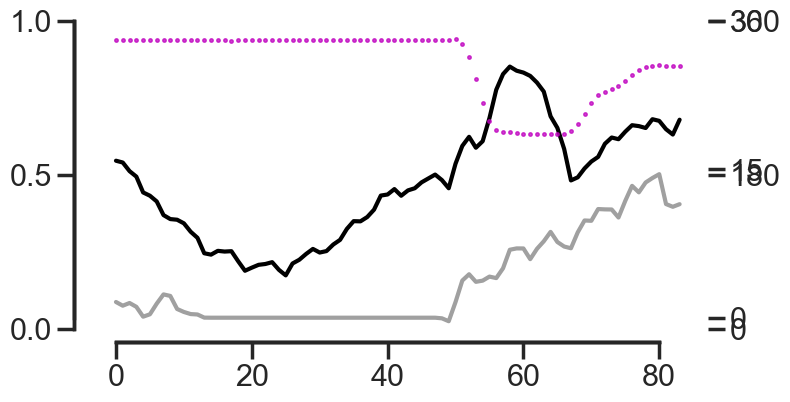

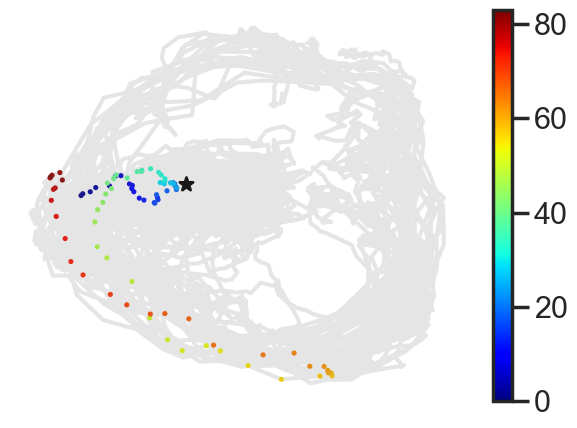

In [13]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
pref_dir_thr = 45 
speed_thr = 5
ep_offset = 30
to_plot = True
# 25s
ep_end = 250

for k in df_emb_hdc.rec_id.unique():
    if 'TS7-HF' not in k:
        continue
    if '20220810_JA180' not in k:
        continue
    print(k)
    dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
    if 'l' in hem:
        hem = 'left'
    else:
        hem = 'right'
    implant = mouse_id + '_' + hem
        
    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    emb_x, emb_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    lin_speed = tmp_df['lin_speed'].values
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = speed_thr)
    # get stat epochs
    stat_epoch = consecutive(stat_idx)

    measured_yaw = tmp_df['measured_yaw'].values
    # compute off manifold ratios
    # _, rad_manifold = compute_radius(emb_x, emb_y)
    rad_manifold = tmp_df['rad_manifold'].values
    rad_manifold_norm = rad_manifold/rad_manifold.max()

    
    for ep_idx, ep in enumerate(stat_epoch):
        # at least 3s and no change in az
        if (len(ep) > 30):
            # if ep_idx != 40:
            #     continue
            start, end = ep[0], ep[:][-1] + ep_offset
            if ep.size > 250:
                end = start + 250
            if rad_manifold_norm[ep[:ep_end]].min() < 0.3:
                offman_ep_flag = True
            else:
                continue
            if ep[0] - ep_offset < 1:
                continue
                
            angles = np.deg2rad(measured_yaw[ep[:ep_end]])
            circmean = stats.circmean(angles)
            circstd = stats.circstd(angles)
            circstd = np.deg2rad(circstd)
            this_yaw = np.rad2deg(circmean)
            if circstd > 1:
                continue
            print(f'{k}, ep idx: {ep_idx}, circmean {this_yaw}, circstd {circstd} min rad {rad_manifold_norm[ep[:ep_end]].min()}')
            print(f'len {len(ep)}, std: {round(np.std(measured_yaw[ep]), 2)}, idx: {start} - {end}')
            offset = rad_manifold_norm[start:end].argmin()
            
            if to_plot == True:
            
                f, ax = plt.subplots(1, figsize = (8, 4))
                ax.plot(rad_manifold_norm[start:end], color = 'k',)
                ax.set_yticks([0, 0.5, 1])
                ax_1 = ax.twinx()
                ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 0.75)
                ax_1.set_yticks([0, 15, 30])
                ax_2 = ax.twinx()
                ax_2.plot( measured_yaw[start:end], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
                ax_2.set_yticks([0, 180, 360])
                sns.despine(offset = 10, trim = True)
                # plt.savefig(f'line_vel_{k}_{ep_idx}.pdf', transparent = True)
                time.sleep(0.2)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = emb_x[start:end], emb_y[start:end]
                u = np.diff(x_tmp)
                v = np.diff(y_tmp)
                pos_x = x_tmp[:-1] + u/2
                pos_y = y_tmp[:-1] + v/2
                norm = np.sqrt(u**2+v**2) 
                plt.plot(emb_x, emb_y, c = 'gray', alpha = 0.2)
                
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:x_tmp.size], 
                            cmap = 'jet')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(emb_x[start + offset], emb_y[start + offset], c = 'k', s = 100, marker = "*")
                plt.axis('off')
                filepath = save_dir / f'scatter_isomap-traj_{k}_{ep_idx}.pdf'
                plt.savefig(filepath, transparent = True)


    #             f.legend(loc='outside upper right')
                f.tight_layout()

                # plt.show()


            print('')
            break
    break
# df_mandyn = pd.concat(ls_df)
# df_mandyn.head()

### Extract epochs using rolling window

In [13]:
d_run_onset = {}

In [14]:
# Skip the epoch-based approach and work directly with continuous data
fs = 10  # Assuming 30 frames per second
speed_threshold = 5  # cm/s
radius_threshold = 0.1  # Relative change threshold
min_separation = fs
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1)
ls_df = [] 

for k in df_emb_hdc.rec_id.unique():
    if 'TS7-HF' not in k:
        continue
    # if '20220804_JA179' not in k:
    #     continue
    print(k)
    # d_run_onset[k] = {}
    
    dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
    if 'l' in hem:
        hem = 'left'
    else:
        hem = 'right'
    implant = mouse_id + '_' + hem
        
    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    emb_x, emb_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    lin_speed = tmp_df['lin_speed'].values
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = speed_threshold)
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True
    cxy, rad_manifold = compute_radius(emb_x, emb_y, run_mask)
    # get stat epochs
    # stat_epoch = consecutive(stat_idx)

    measured_yaw = tmp_df['measured_yaw'].values
    measured_yaw_rad = np.deg2rad(measured_yaw)
    # compute off manifold ratios
    # _, rad_manifold = compute_radius(emb_x, emb_y)
    # rad_manifold = tmp_df['rad_manifold'].values
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    # Find movement onset events with clean preceding stationary periods
    onset_events = []
    i = fs*3  # Start after first 3 seconds
    
    while i < len(lin_speed) - fs*3:  # Skip last 3 seconds
        # Check if this is a transition from stationary to moving
        if (np.mean(lin_speed[i-10:i]) < 1 and 
            np.mean(lin_speed[i:i+5]) > 4):
        
            # Stable heading
            # circmean = stats.circmean(measured_yaw_rad[i-5:i+10])
            circstd = stats.circstd(measured_yaw_rad[i-15:i+10])
            circstd = np.rad2deg(circstd)
            if circstd > 3:
                # print(f'circstd {circstd}')
                i += 1 
                continue
            
            
            # Find the precise frame where speed crosses threshold
            onset_frame = None
            for j in range(i-5, i+5):
                if lin_speed[j] > speed_threshold:
                    onset_frame = j
                    break
            
            if onset_frame is not None:
                onset_events.append(onset_frame)
                # Skip ahead to avoid double counting nearby transitions
                i = onset_frame + min_separation
                
            else:
                i += 1
        else:
            i += 1
    
    # For each onset event, extract a window of data
    pre_frames = 15  # 1.5 seconds before
    post_frames = 20  # 2 seconds after
    # aligned_speed = []
    # aligned_radius = []
    # aligned_yaw = []
    for onset in onset_events:
        if onset > pre_frames and onset + post_frames < len(lin_speed):
            window = np.arange(onset - pre_frames, onset + post_frames)
            # choose epochs with off ring dynamics
            if rad_manifold_norm[window].min() > 0.4:
                continue
            epoch_id = rec_session + '_' + str(onset)
            tmp_df = pd.DataFrame({'epoch_id':epoch_id, 'epoch_speed': lin_speed[window], 'epoch_ring_rad': rad_manifold_norm[window], 'epoch_yaw': measured_yaw[window],
                                  'epoch_emb_x': emb_x[window], 'epoch_emb_y': emb_y[window], 'time':t, 'rec_id':k    })
            ls_df.append(tmp_df)
            # aligned_speed.append(lin_speed[window])
            # aligned_radius.append(rad_manifold_norm[window])
            # aligned_yaw.append(measured_yaw[window])
            
    # Convert to arrays
    # aligned_speed = np.array(aligned_speed)
    # aligned_radius = np.array(aligned_radius)
    # aligned_yaw = np.array(aligned_yaw)
    # print(f'rec {k} shape {aligned_speed.shape}' )
    
    # d_run_onset[k]['aligned_speed'] = aligned_speed
    # d_run_onset[k]['aligned_radius'] = aligned_radius
    # d_run_onset[k]['aligned_yaw'] = aligned_yaw

    
    # Calculate average traces
    # mean_speed = np.mean(aligned_speed, axis=0)
    # mean_radius = np.mean(aligned_radius, axis=0)
    # sem_speed = np.std(aligned_speed, axis=0) / np.sqrt(len(onset_events))
    # sem_radius = np.std(aligned_radius, axis=0) / np.sqrt(len(onset_events))

    # break
df_stat2run = pd.concat(ls_df)
df_stat2run.head()

20220819_JA178_lADN_red_H2_VR1_TS7-HF
20220823_JA178_lADN_red_H2_VR1_TS7-HF
20220907_JA178_rADN_yel_H2_VR1_TS7-HF
20220802_JA179_lADN_red_H2_VR1_TS7-HF
20220804_JA179_lADN_red_H2_VR1_TS7-HF
20220805_JA179_lADN_red_H2_VR1_TS7-HF
20220809_JA180_lADN_red_H2_VR1_TS7-HF
20220810_JA180_lADN_red_H2_VR1_TS7-HF
20220811_JA180_lADN_red_H2_VR1_TS7-HF
20220819_JA180_lADN_red_H2_VR1_TS7-HF
20220809_JA181_lADN_red_H2_VR1_TS7-HF
20220812_JA181_lADN_red_H2_VR1_TS7-HF
20220627_MC022_lADN_red_H2_VR1_TS7-HF
20220629_MC022_lADN_red_H2_VR1_TS7-HF
20220829_MC038_lADN_red_H2_VR1_TS7-HF


,epoch_id,epoch_speed,epoch_ring_rad,epoch_yaw,epoch_emb_x,epoch_emb_y,time,rec_id
0,JA179_20220802_4856,0.0,0.381106,53.637816,6.551869,-7.215268,-1.5,20220802_JA179_lADN_red_H2_VR1_TS7-HF
1,JA179_20220802_4856,0.0,0.418789,53.554116,6.810913,-8.360899,-1.4,20220802_JA179_lADN_red_H2_VR1_TS7-HF
2,JA179_20220802_4856,0.0,0.408994,53.563475,6.788127,-8.070040,-1.3,20220802_JA179_lADN_red_H2_VR1_TS7-HF
3,JA179_20220802_4856,0.0,0.409921,53.674933,6.912098,-8.111912,-1.2,20220802_JA179_lADN_red_H2_VR1_TS7-HF
4,JA179_20220802_4856,0.0,0.413435,53.669390,6.894665,-8.213193,-1.1,20220802_JA179_lADN_red_H2_VR1_TS7-HF


In [87]:
df_stat2run.epoch_id.unique().size

55

#### Extract epochs using stat/run

20220819_JA178_lADN_red_H2_VR1_TS7-HF
High circ std 10.311753441776027
High circ std 23.678124199796454
High circ std 35.34662337585507
High circ std 16.014675963775147
20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 37, circmean 297.58781522610974, circstd 1.293720761154515 min rad 0.36261820019708674
len 100, std: 0.17, idx: 4069 - 4109
bad epoch (False, {'perr_t0': 60369.37254152439, 'r2': 0.7461605933205059, 'k': 0.8080102233042595, 't0': 14.719172901770047, 'amp': 691490.6528799708}) (True, {'perr_t0': 0.07012365901358084, 'r2': 0.8825073761333169, 'k': 4.979502397745579, 't0': -0.7778063891078482, 'amp': 0.20422820673498027})
20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 41, circmean 221.3875478760689, circstd 0.22244837514854665 min rad 0.2548765959042433
len 170, std: 0.08, idx: 4479 - 4519
bad epoch (True, {'perr_t0': 0.01843701405118268, 'r2': 0.9473253093374872, 'k': 29.35188150598965, 't0': 0.06959137629037088, 'amp': 11.366236471433142}) (False, {'perr_t0': 0.5372611416858

C:\Users\01\anaconda3\envs\py39\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


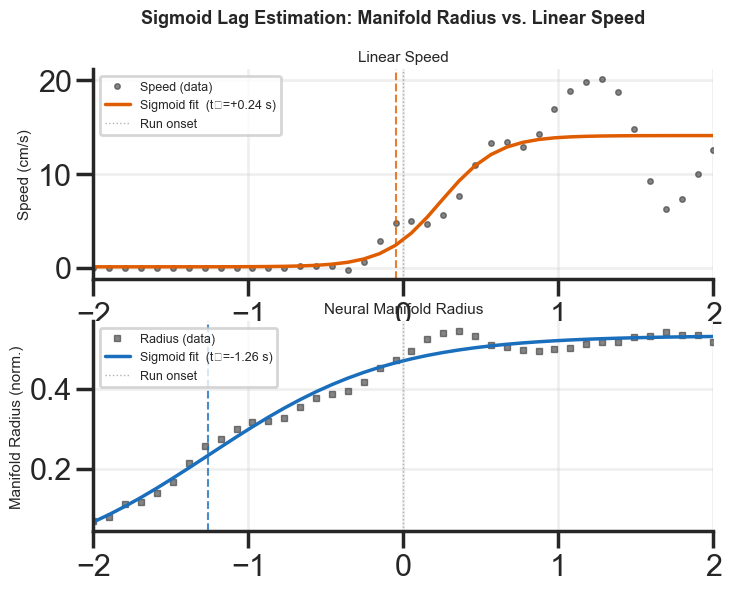

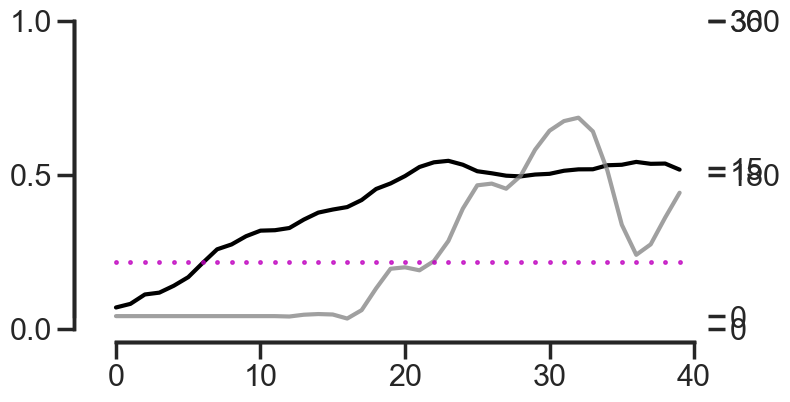

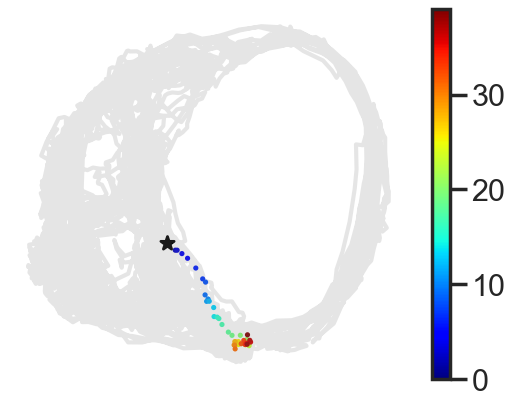


20220804_JA179_lADN_red_H2_VR1_TS7-HF
20220804_JA179_lADN_red_H2_VR1_TS7-HF, ep idx: 3, circmean 46.2411473902661, circstd 0.08642800998160492 min rad 0.28784559825963985
len 45, std: 0.05, idx: 289 - 329
bad epoch (True, {'perr_t0': 0.057048077218253126, 'r2': 0.704839000955374, 'k': 22.991601784902045, 't0': 0.18315465996181382, 'amp': 6.787101585508235}) (False, {'perr_t0': 0.09946073508232196, 'r2': 0.6337015013708162, 'k': 10.464770015493166, 't0': 0.16900287462097133, 'amp': -0.20782856649425355})
Base lin speed 2.5214700907537346, onset 12.75349722544479
20220804_JA179_lADN_red_H2_VR1_TS7-HF, ep idx: 10, circmean 47.41936004450956, circstd 0.055323059943731434 min rad 0.285902619413305
len 70, std: 0.07, idx: 1084 - 1124
good epoch (True, {'perr_t0': 0.014142260526495865, 'r2': 0.9949912617471052, 'k': 4.759100255257508, 't0': 0.6480055264368255, 'amp': 36.308737846977166}) (True, {'perr_t0': 0.03266039073152945, 'r2': 0.9694756546626048, 'k': 5.634951878199151, 't0': 0.0099844

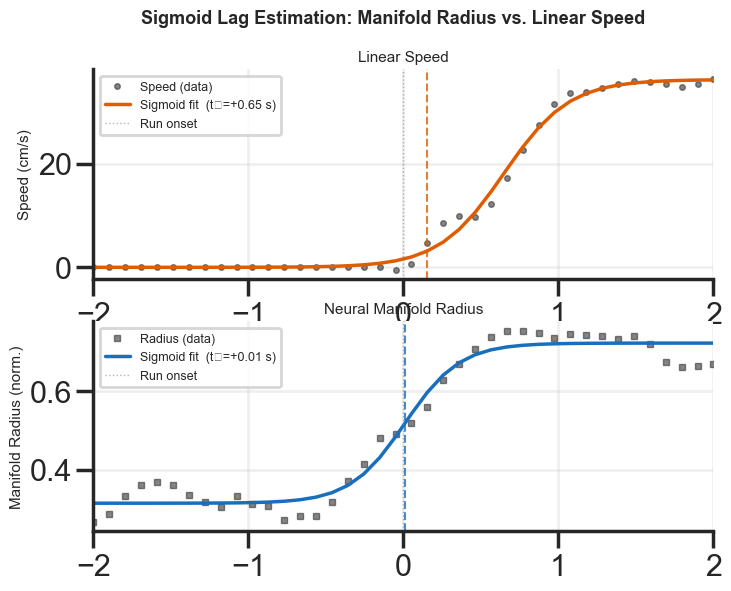

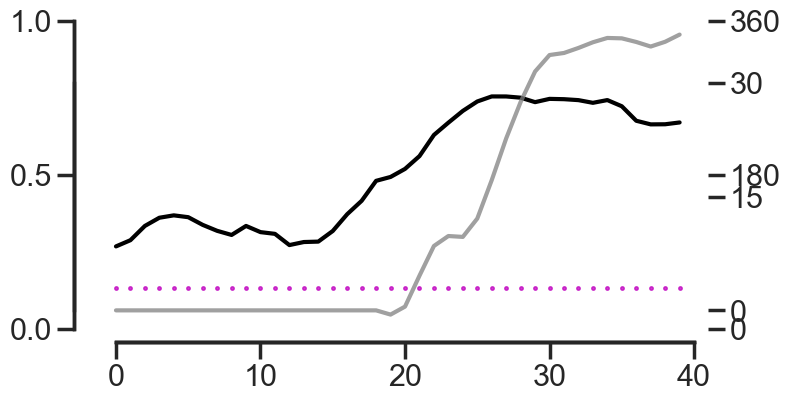

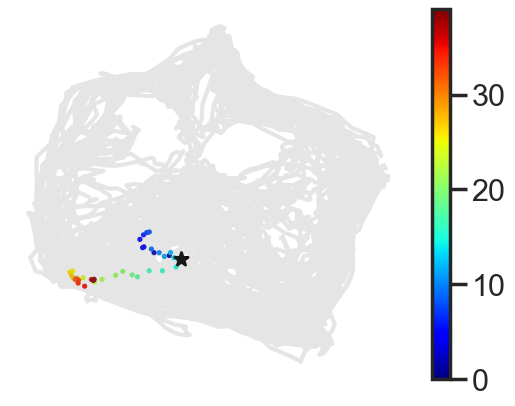


20220805_JA179_lADN_red_H2_VR1_TS7-HF
High circ std 34.246058600758445
High circ std 20.112490431169
High circ std 47.34741112309912
High circ std 60.129379656315436
High circ std 35.798326547859034
High circ std 40.94973988228002
High circ std 31.652200315409445
High circ std 45.647327110483644
High circ std 96.36615989754978
High circ std 43.08923603048493
High circ std 15.990877497530041
20220805_JA179_lADN_red_H2_VR1_TS7-HF, ep idx: 50, circmean 41.96298671982265, circstd 2.1504269022183764 min rad 0.6296311262467215
len 130, std: 19.13, idx: 6979 - 7019
good epoch (True, {'perr_t0': 0.10661674104748824, 'r2': 0.41586031296480686, 'k': 22.581293599775453, 't0': 0.214344788135985, 'amp': 6.590126558332321}) (True, {'perr_t0': 0.0893029587134283, 'r2': 0.6404347400617114, 'k': 12.14436743836661, 't0': -0.40074898250004914, 'amp': 0.2343933284113688})
Speed  sigmoid midpoint  t0 = +0.214 s  (±0.107)
Radius sigmoid midpoint  t0 = -0.401 s  (±0.089)
Estimated lag (radius - speed): -657

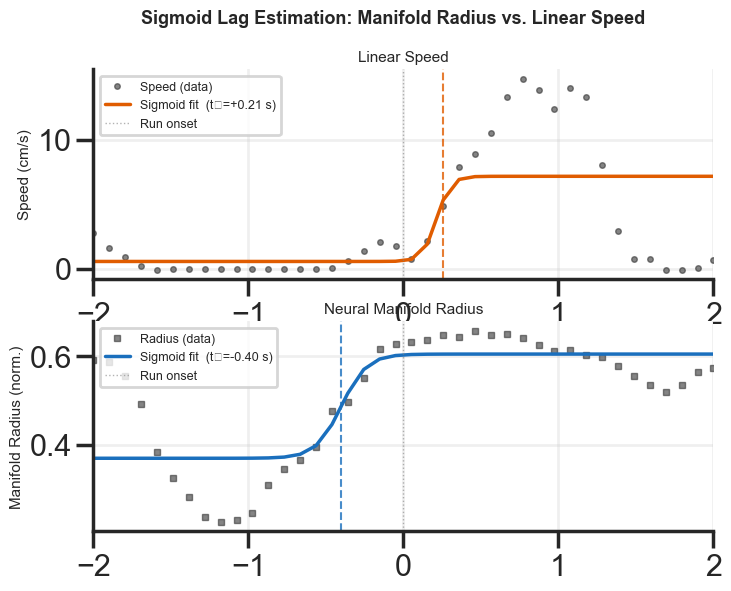

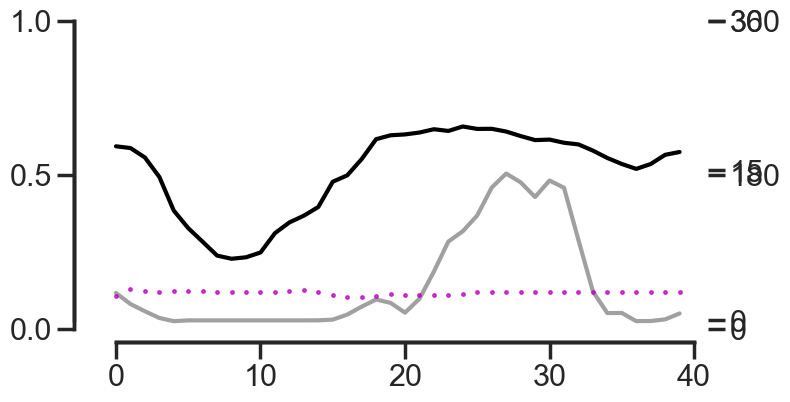

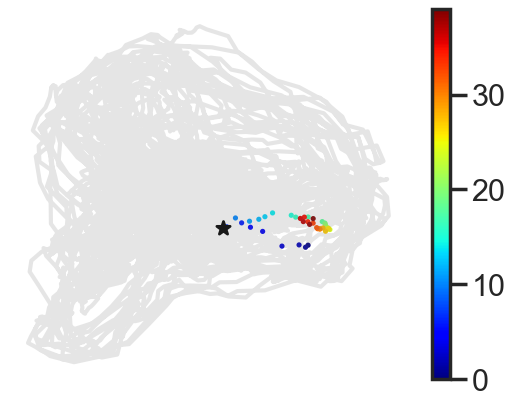


20220809_JA180_lADN_red_H2_VR1_TS7-HF
High circ std 55.27254017258727
High circ std 45.87376969714394
High circ std 44.175945699167606
High circ std 41.16887477798559
High circ std 10.4699562304888
High circ std 7.991542765254491
20220809_JA180_lADN_red_H2_VR1_TS7-HF, ep idx: 28, circmean 3.9866596955916607, circstd 2.169203331022017 min rad 0.44129883571130357
len 195, std: 28.21, idx: 5124 - 5164
good epoch (True, {'perr_t0': 0.014297971800951183, 'r2': 0.9809985497192222, 'k': 16.763252125133093, 't0': -0.11305567319427576, 'amp': 7.005176335925723}) (True, {'perr_t0': 0.029751574227670587, 'r2': 0.9650717054988589, 'k': 7.546970127059307, 't0': -0.04111038198538633, 'amp': 0.4112781876453416})
Speed  sigmoid midpoint  t0 = -0.113 s  (±0.014)
Radius sigmoid midpoint  t0 = -0.041 s  (±0.030)
Estimated lag (radius - speed): +112.7 ms


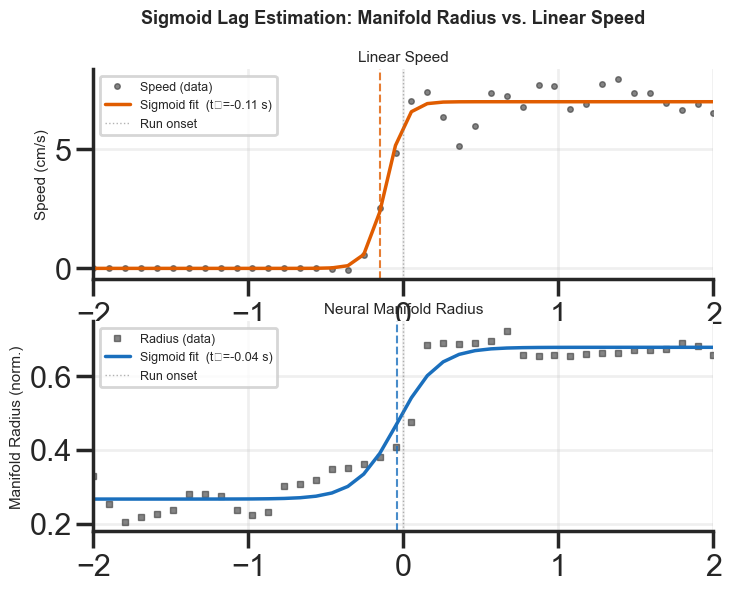

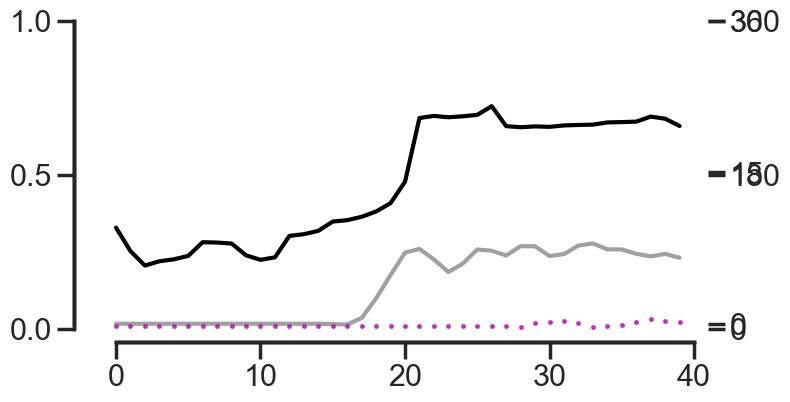

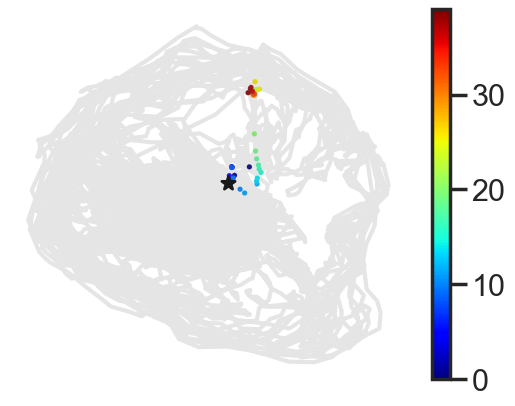


20220810_JA180_lADN_red_H2_VR1_TS7-HF
High circ std 60.13576419068311
High circ std 46.49511994975882
High circ std 85.53011575984632
High circ std 51.472152539010516
20220810_JA180_lADN_red_H2_VR1_TS7-HF, ep idx: 16, circmean 307.5136538731353, circstd 0.10070033190593057 min rad 0.05514808906660169
len 685, std: 0.09, idx: 2114 - 2154
good epoch (True, {'perr_t0': 0.03530601418346466, 'r2': 0.9771209170829567, 'k': 3.8588949297453685, 't0': 0.25246478377009957, 'amp': 13.057766580874498}) (True, {'perr_t0': 0.04614430249482652, 'r2': 0.939229650269146, 'k': 5.726910077363197, 't0': -0.2603991184730763, 'amp': 0.4304467986416803})
Speed  sigmoid midpoint  t0 = +0.252 s  (±0.035)
Radius sigmoid midpoint  t0 = -0.260 s  (±0.046)
Estimated lag (radius - speed): -106.6 ms


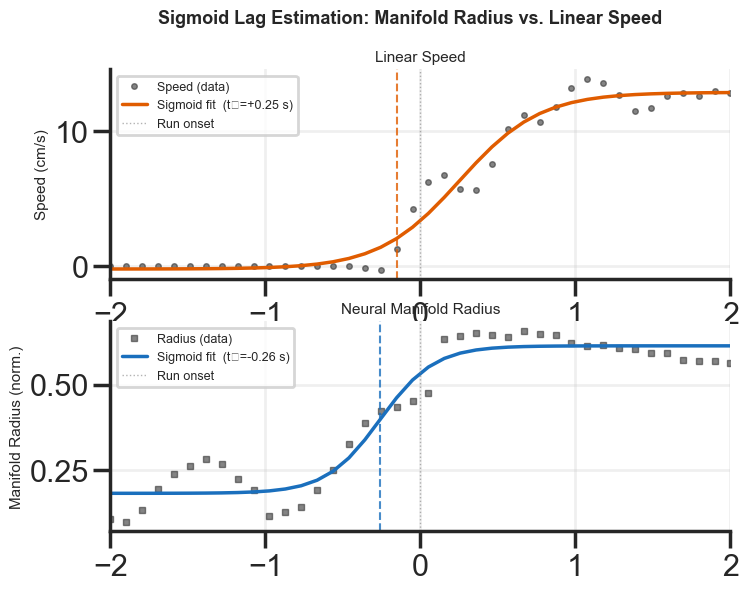

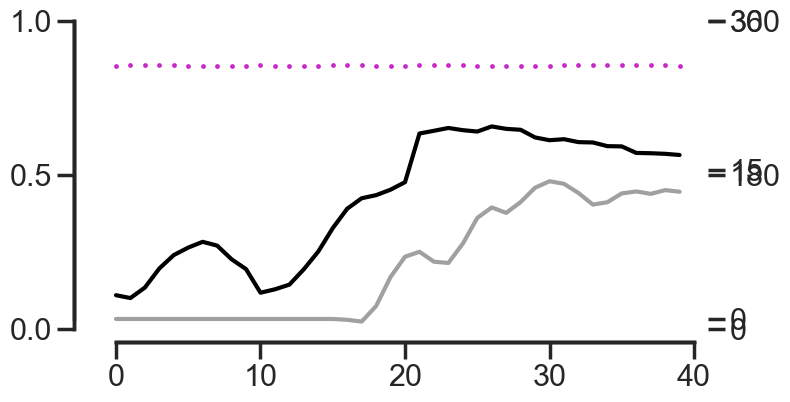

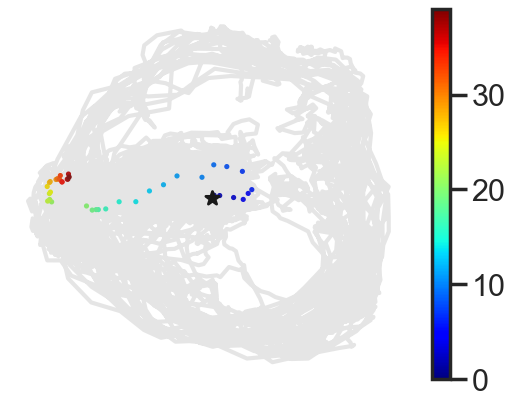


20220811_JA180_lADN_red_H2_VR1_TS7-HF
High circ std 38.35684286200599
20220811_JA180_lADN_red_H2_VR1_TS7-HF, ep idx: 3, circmean 261.7338709539746, circstd 0.5974540110855254 min rad 0.05021791517722353
len 125, std: 0.09, idx: 319 - 359
good epoch (True, {'perr_t0': 0.03966738139367571, 'r2': 0.959749766313077, 'k': 5.108548516798766, 't0': 0.2911842064908492, 'amp': 20.259889573385987}) (True, {'perr_t0': 0.03629119253870677, 'r2': 0.978941721496623, 'k': 3.5460374057480646, 't0': -0.5811278704072778, 'amp': 0.36104988817525563})
Speed  sigmoid midpoint  t0 = +0.291 s  (±0.040)
Radius sigmoid midpoint  t0 = -0.581 s  (±0.036)
Estimated lag (radius - speed): -529.8 ms


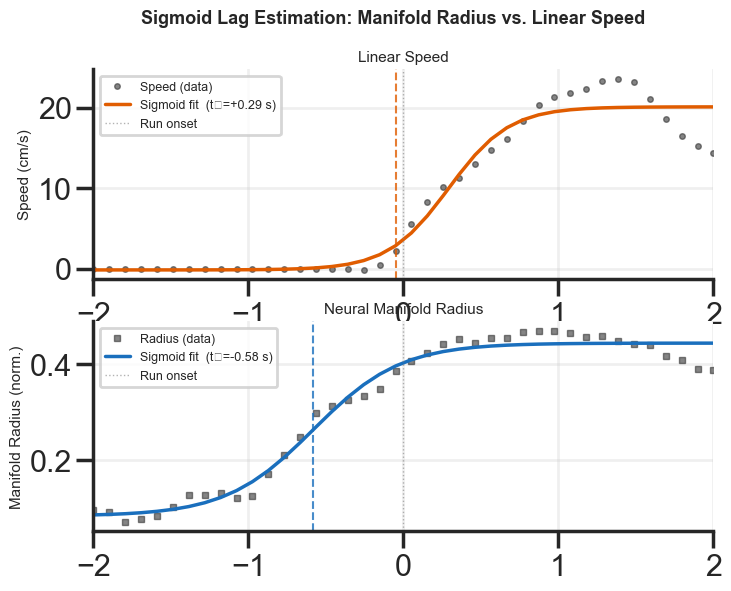

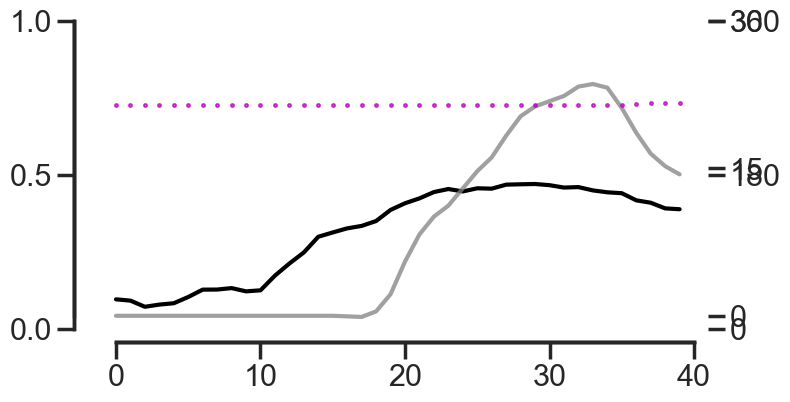

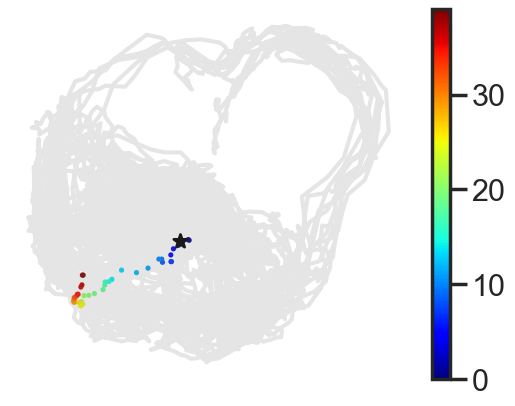


20220819_JA180_lADN_red_H2_VR1_TS7-HF
High circ std 92.58369949594807
High circ std 84.47345643682091
20220809_JA181_lADN_red_H2_VR1_TS7-HF
High circ std 65.0155546203973
High circ std 52.65641948549485
High circ std 49.391860206609195
20220809_JA181_lADN_red_H2_VR1_TS7-HF, ep idx: 31, circmean 331.45107012464393, circstd 1.5212874793527973 min rad 0.16840380450393508
len 115, std: 0.29, idx: 8534 - 8574
bad epoch (False, {'perr_t0': 0.10853081443506978, 'r2': 0.39131174407641345, 'k': 20.905780417215176, 't0': -0.6957352810328168, 'amp': 3.4402848838338156}) (True, {'perr_t0': 0.042600845203998504, 'r2': 0.9306081950526495, 'k': 7.452575321478635, 't0': -0.3130587580316035, 'amp': 0.4060206515336321})
High circ std 29.666792619978658
High circ std 54.09856514847953
Base lin speed 0.0, onset 0.0
20220812_JA181_lADN_red_H2_VR1_TS7-HF
High circ std 15.216652464565518
High circ std 30.31329623647385
20220812_JA181_lADN_red_H2_VR1_TS7-HF, ep idx: 23, circmean 186.7419794570938, circstd 0.

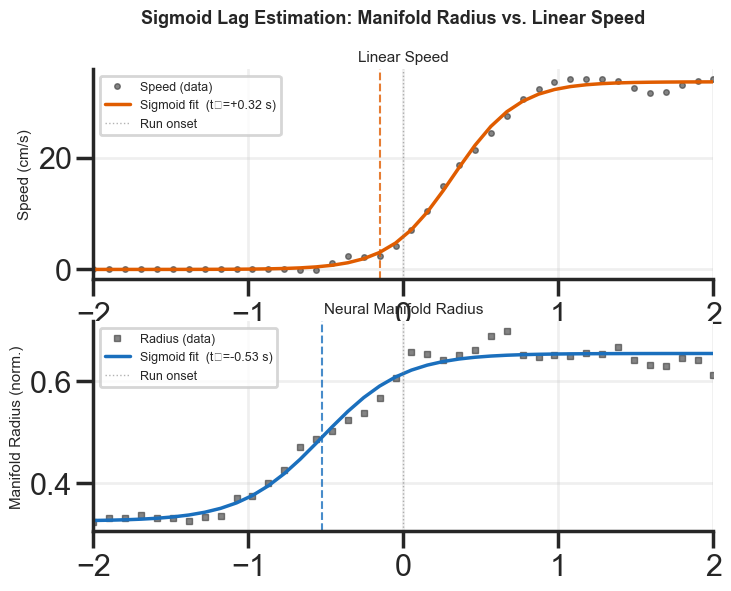

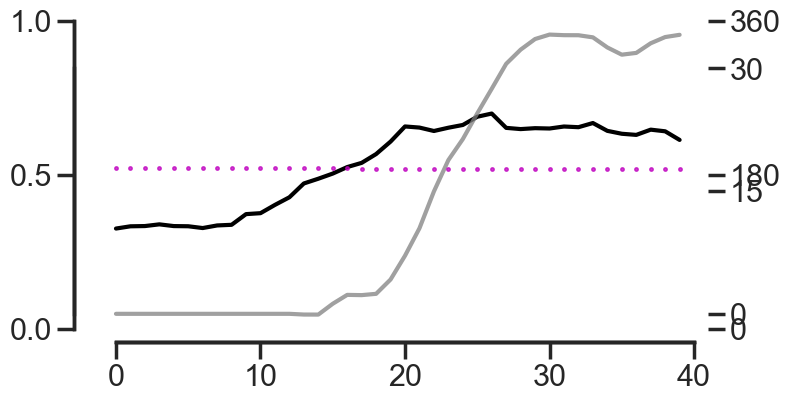

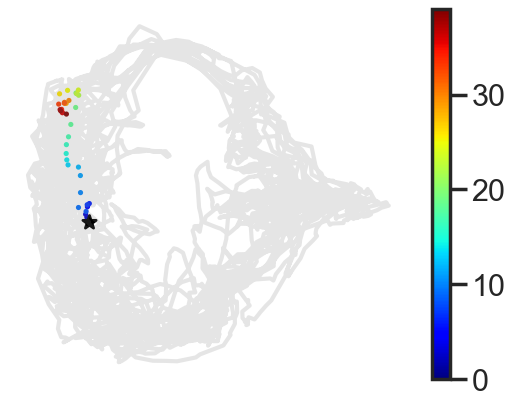


20220627_MC022_lADN_red_H2_VR1_TS7-HF
High circ std 23.678070656580235
High circ std 59.4606497772668
20220627_MC022_lADN_red_H2_VR1_TS7-HF, ep idx: 103, circmean 50.7313758718558, circstd 1.1619296100549448 min rad 0.48029628580040473
len 115, std: 0.64, idx: 9389 - 9429
good epoch (True, {'perr_t0': 0.06241625066457312, 'r2': 0.8384106501854004, 'k': 8.874050176280178, 't0': -0.274268566261149, 'amp': 5.8391876663091145}) (True, {'perr_t0': 0.09724699332126482, 'r2': 0.9444581274440759, 'k': 2.001740822754596, 't0': -0.32883448755732503, 'amp': 0.2823865844713532})
Speed  sigmoid midpoint  t0 = -0.274 s  (±0.062)
Radius sigmoid midpoint  t0 = -0.329 s  (±0.097)
Estimated lag (radius - speed): -72.4 ms


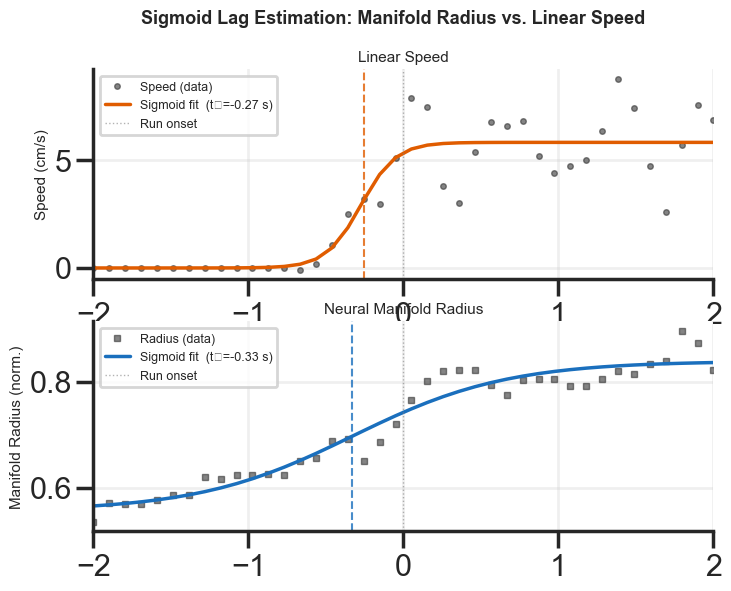

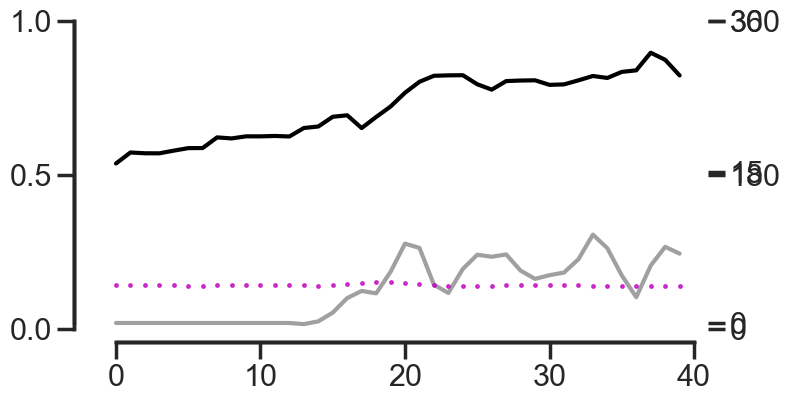

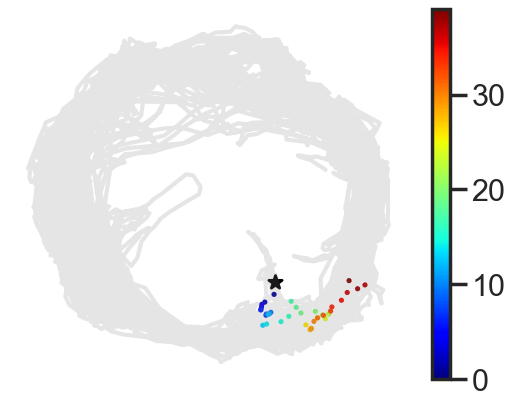


20220629_MC022_lADN_red_H2_VR1_TS7-HF
High circ std 24.312754365500545
High circ std 18.266763572662175
High circ std 15.149348112019563
High circ std 13.965647002523847
Base lin speed 2.038346422179259, onset 5.180696839359702
20220829_MC038_lADN_red_H2_VR1_TS7-HF
High circ std 29.829632682241513
High circ std 5.651852355669613
High circ std 30.653319199038382
High circ std 9.119916451750628
High circ std 49.67473097500489
High circ std 40.30684122821334
High circ std 29.636407711685525
High circ std 40.212747970711064
High circ std 34.159382451135855
Base lin speed 0.0, onset 2.803630721142107
High circ std 33.896036397432574
High circ std 20.032454945717706
High circ std 39.25881428477773
High circ std 14.699231258786082
High circ std 19.706438481296708
Base lin speed 0.08933086309178728, onset 0.0


In [14]:
ls_df = []
speed_thr = 5
ep_offset = 30
to_plot = True
# 25s
ep_end = 40
n_samples = 40   # samples per epoch
t = np.linspace(-2, 2, n_samples)   # 4 s window centred on run onset
ls_lag, ls_df = [], []

for k in df_emb_hdc.rec_id.unique():
    if 'TS7-HF' not in k:
        continue
    # if '20220804_JA179' not in k:
    #     continue
    print(k)

    
    dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
    if 'l' in hem:
        hem = 'left'
    else:
        hem = 'right'
    implant = mouse_id + '_' + hem
        
    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    emb_x, emb_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    lin_speed = tmp_df['lin_speed'].values


    measured_yaw = tmp_df['measured_yaw'].values
    measured_yaw_rad = np.deg2rad(measured_yaw)
    # compute off manifold ratios
    # _, rad_manifold = compute_radius(emb_x, emb_y)
    rad_manifold = tmp_df['rad_manifold'].values
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    
    # find stat, run, rot epochs
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        # _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
    # get stat epochs
    stat_epoch = consecutive(stat_idx)
    run_epoch = consecutive(run_idx)
    
    for ep_idx, ep in enumerate(stat_epoch):
        # at least 3s and no change in az
        if (len(ep) > 40):
            # if ep_idx != 114:
            #     continue
            start, end = ep[-1]-20, ep[-1] + 20
            if ep.size > 250:
                end = start + ep_end
            if rad_manifold_norm[start:end].max() - rad_manifold_norm[start:end].min() > 0.3:
                offman_ep_flag = True
            else:
                continue
            if ep[0] - ep_offset < 1:
                continue
                
            angles = np.deg2rad(measured_yaw[start:end])
            circstd = stats.circstd(angles)
            circmean = stats.circmean(angles)
            circstd = np.rad2deg(circstd)
            this_yaw = np.rad2deg(circmean)
           
            if circstd > 3:
                print(f'High circ std {circstd}')
                continue
            baseline_speed = lin_speed[start:ep[-1]].mean()
            onset_speed = lin_speed[ep[-1]: ep[-1] + 5].mean()
            if  baseline_speed > 2 or onset_speed < 4:
                print(f'Base lin speed {baseline_speed}, onset {onset_speed}')
                continue
            # if angles.size != 40:
            #     continue
            print(f'{k}, ep idx: {ep_idx}, circmean {this_yaw}, circstd {circstd} min rad {rad_manifold_norm[ep[:ep_end]].min()}')
            print(f'len {len(ep)}, std: {round(np.std(measured_yaw[ep]), 2)}, idx: {start} - {end}')
            offset = rad_manifold_norm[start:end].argmin()

            # Convert to arrays
            # aligned_speed.append(lin_speed[start:end])
            # aligned_radius.append(rad_manifold_norm[start:end])
            # aligned_yaw.append(measured_yaw[start:end])

            speed = lin_speed[start:end]
            radius = rad_manifold_norm[start:end]
            epoch_yaw =  measured_yaw[start:end]

            p0_speed  = [0.0,  4.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
            p0_radius = [-0.5, 3.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
            
            popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
            popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
            
            t0_speed  = popt_s[0] if popt_s is not None else np.nan
            t0_radius = popt_r[0] if popt_r is not None else np.nan
            if fit_s.max() < 3:
                print(f'Low speed fit {fit_s.max()}')
                continue
            # define spped onset as fit speed crossing 2cm/s
            speed_onset_t = t[np.where(fit_s > 2)[0][0]]
            lag = t0_radius - speed_onset_t   # negative → radius leads speed
            perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
            perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4

            is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
            is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

            if is_good_speed[0] & is_good_rad[0]:
                print(f'good epoch {is_good_speed} {is_good_rad}')
            else:
                print(f'bad epoch {is_good_speed} {is_good_rad}')
                continue
            
            print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
            print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
            print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
            
            ls_lag.append(lag)
            tmp_df = pd.DataFrame({'rec_id': k, 'epoch': ep_idx, 'aligned_speed': speed, 'speed_onset_t': speed_onset_t, 'fit_s':fit_s, 'lag': lag,
                          'aligned_yaw':epoch_yaw, 'aligned_radius': radius, 'fit_r':fit_r, 't0_radius':t0_radius, 'time':t,
                          })
            ls_df.append(tmp_df)
    

            if to_plot == True:

                fig, axes = plt.subplots(2, 1, figsize=(8, 6))
                fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                             fontsize=13, fontweight='bold', y=0.98)
                
                # --- Panel 1: Speed ---
                ax = axes[0]
                ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
                ax.plot(t, fit_s, '-', color='#e05c00', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
                ax.axvline(speed_onset_t, color='#e05c00', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Speed (cm/s)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Linear Speed', fontsize=11)
                ax.grid(True, alpha=0.3)
                
                # --- Panel 2: Radius ---
                ax = axes[1]
                ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
                ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
                ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Neural Manifold Radius', fontsize=11)
                ax.grid(True, alpha=0.3)


                f, ax = plt.subplots(1, figsize = (8, 4))
                ax.plot(rad_manifold_norm[start:end], color = 'k',)
                ax.set_yticks([0, 0.5, 1])
                ax_1 = ax.twinx()
                ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 0.75)
                ax_1.set_yticks([0, 15, 30])
                ax_2 = ax.twinx()
                ax_2.plot( measured_yaw[start:end], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
                ax_2.set_yticks([0, 180, 360])
                sns.despine(offset = 10, trim = True)
                # plt.savefig(f'line_vel_{k}_{ep_idx}.pdf', transparent = True)
                time.sleep(0.2)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = emb_x[start:end], emb_y[start:end]
                u = np.diff(x_tmp)
                v = np.diff(y_tmp)
                pos_x = x_tmp[:-1] + u/2
                pos_y = y_tmp[:-1] + v/2
                norm = np.sqrt(u**2+v**2) 
                plt.plot(emb_x[:], emb_y[:], c = 'gray', alpha = 0.2)
                
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:x_tmp.size], 
                            cmap = 'jet')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(emb_x[start + offset], emb_y[start + offset], c = 'k', s = 100, marker = "*")
                plt.axis('off')
                # plt.savefig(f'scatter_isomap-traj_{k}_{ep_idx}.pdf', transparent = True)

    #             f.legend(loc='outside upper right')
                # f.tight_layout()

                plt.show()
                print('')
            break



        
    #     break
    # break
# df_run_onset = pd.concat(ls_df)
# df_run_onset.head()

#### Using xcorr

20220819_JA178_lADN_red_H2_VR1_TS7-HF
0
0.094 0.7
1
0.004 -0.5


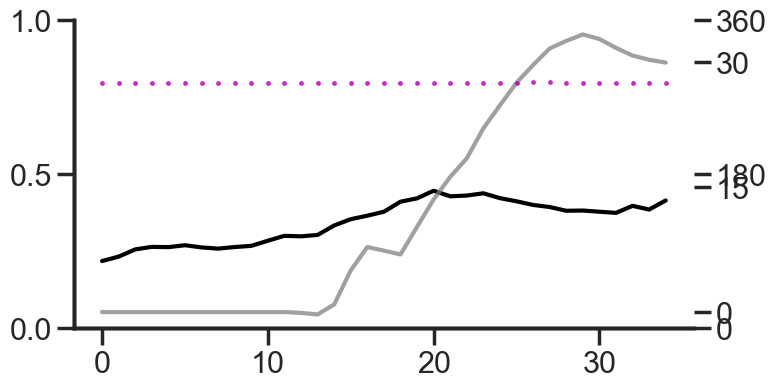

2
0.006 -0.1


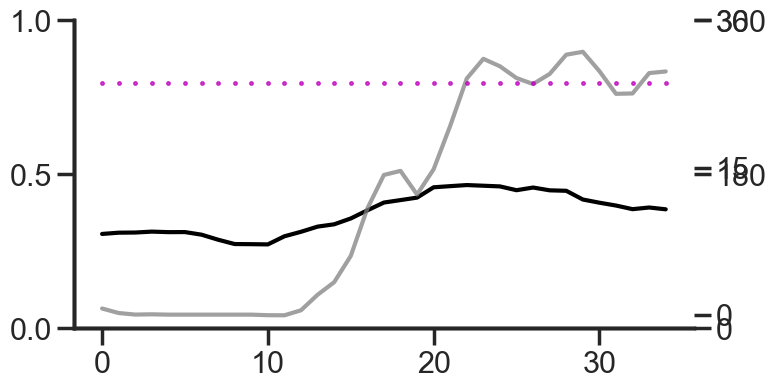

3
0.974 -1.7
4
0.938 -0.3
5
0.19 0.1
6
0.604 0.8
7
0.95 0.3
20220823_JA178_lADN_red_H2_VR1_TS7-HF
20220907_JA178_rADN_yel_H2_VR1_TS7-HF
20220802_JA179_lADN_red_H2_VR1_TS7-HF
0
0.276 -0.8
1
0.684 -0.5
2
0.75 -1.0
3
0.168 -0.4
4
0.332 -0.7
5
0.754 -0.2
6
0.038 0.1


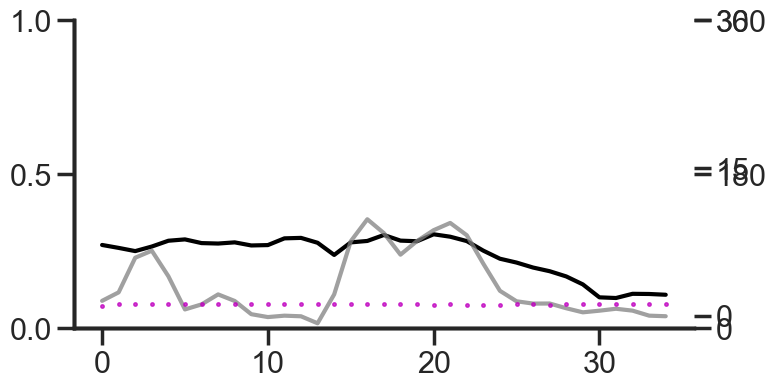

7
0.668 -0.2
8
0.006 -1.0


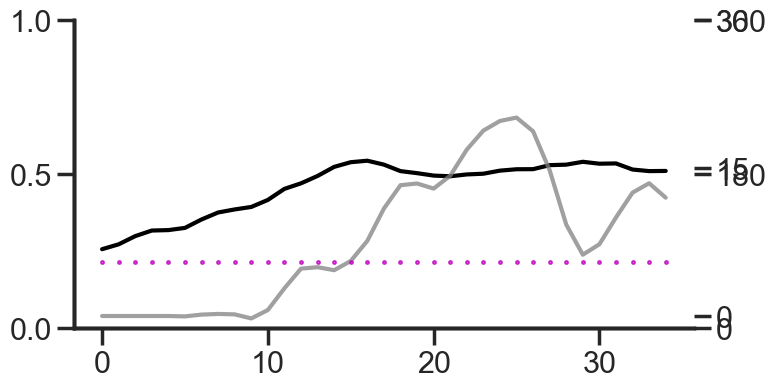

20220804_JA179_lADN_red_H2_VR1_TS7-HF
0
0.506 -2.0
1
0.0 -0.5


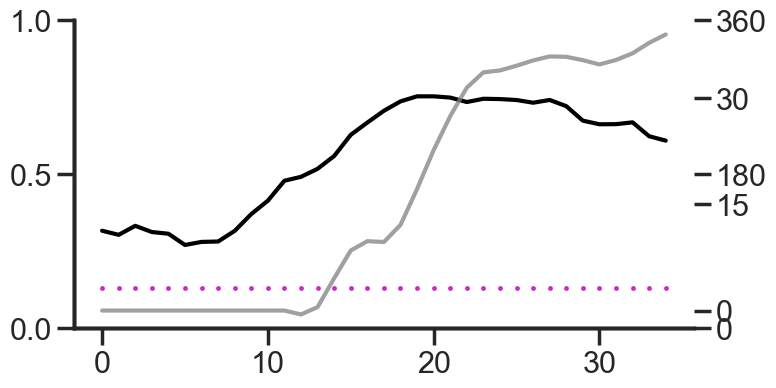

2
0.0 -0.5


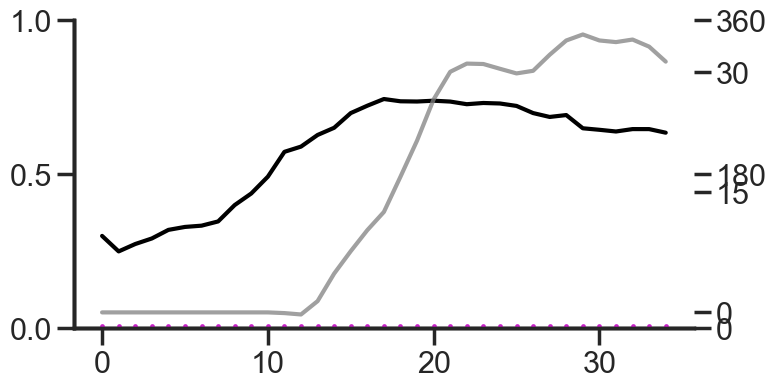

3
0.002 -1.1


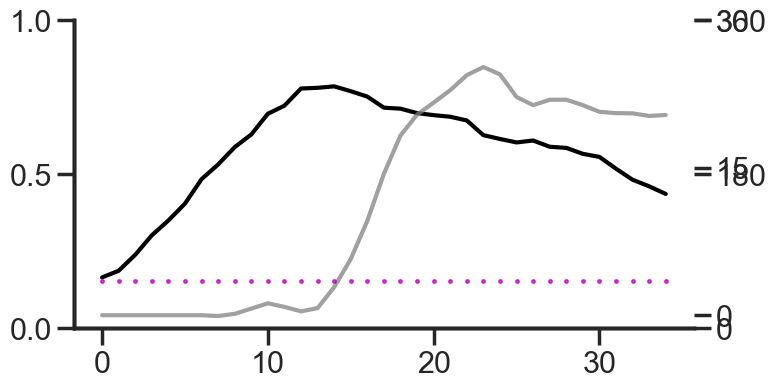

4
0.0 -0.6


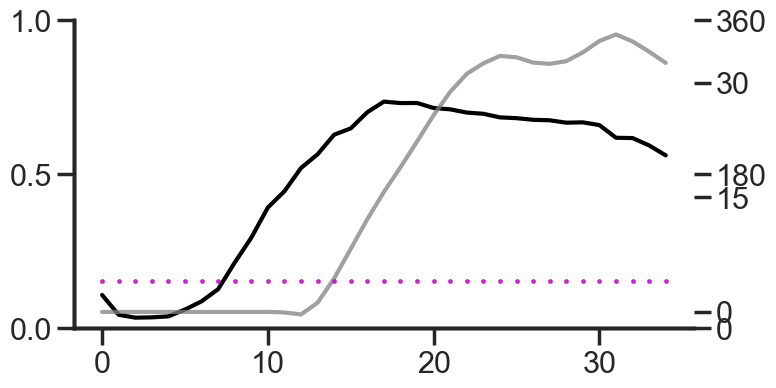

5
0.128 1.4
6
0.0 -0.7


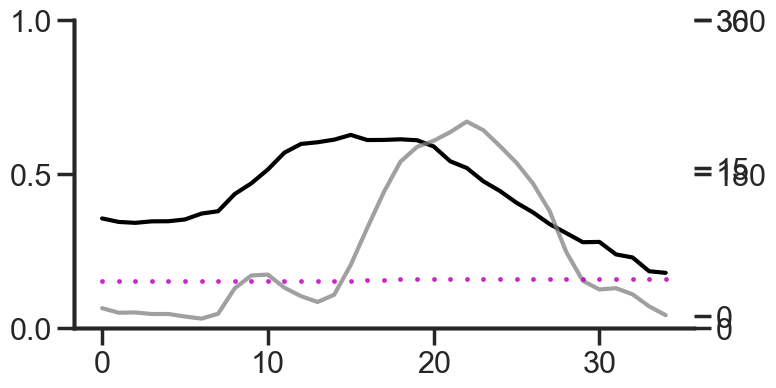

7
0.344 -0.3
20220805_JA179_lADN_red_H2_VR1_TS7-HF
0
0.024 0.6


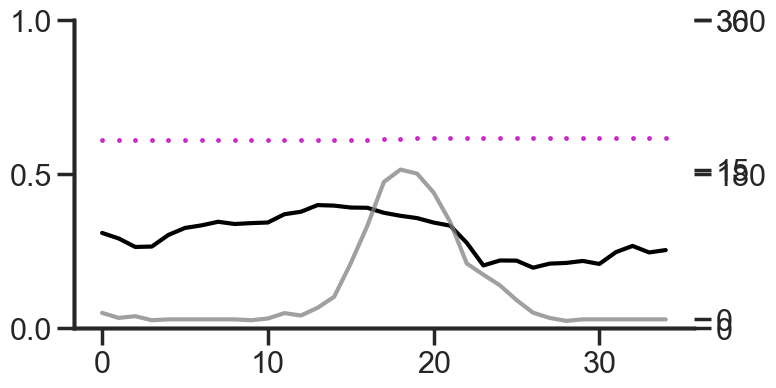

1
0.08 -0.3
2
0.004 -1.5


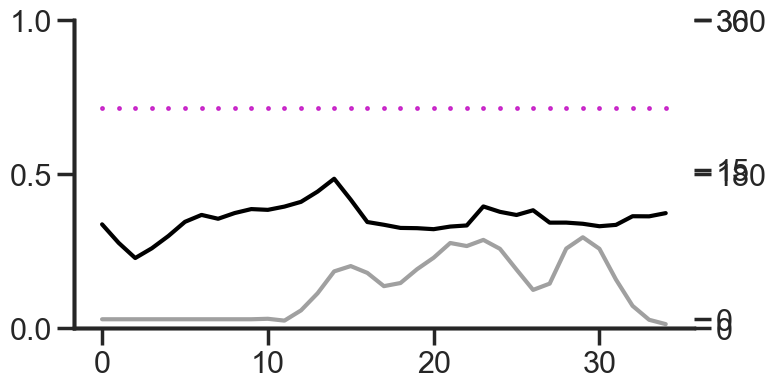

3
0.27 -1.6
20220809_JA180_lADN_red_H2_VR1_TS7-HF
0
0.412 0.4
1
0.016 0.1


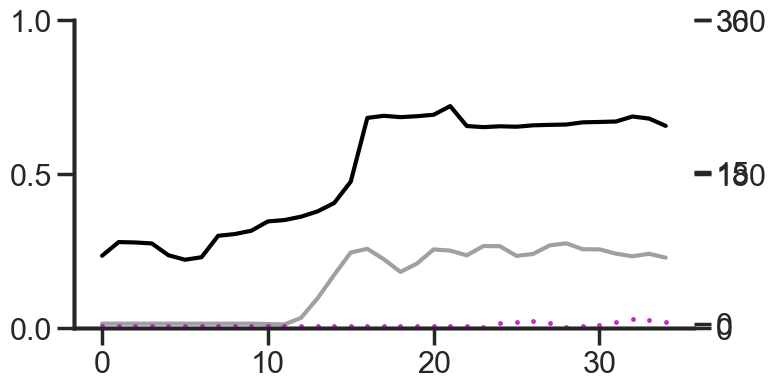

2
0.232 -1.2
3
0.602 -1.0
20220810_JA180_lADN_red_H2_VR1_TS7-HF
0
0.006 -0.4


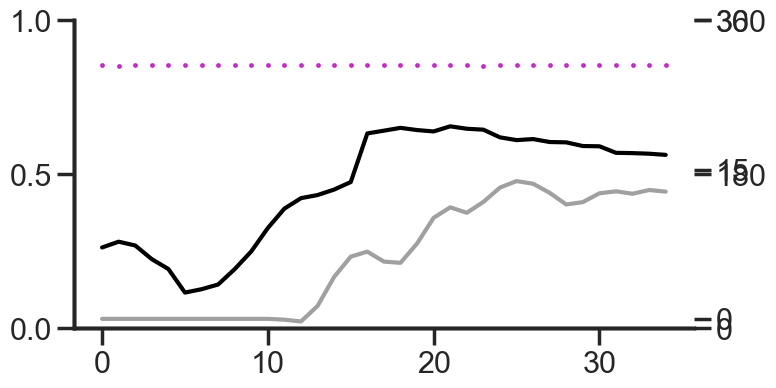

1
0.45 -1.1
2
0.58 -0.6
3
0.096 -1.7
20220811_JA180_lADN_red_H2_VR1_TS7-HF
0
0.004 -0.8


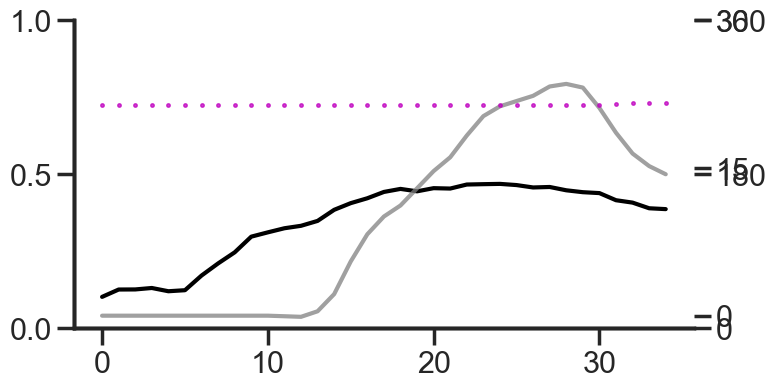

1
0.04 0.2


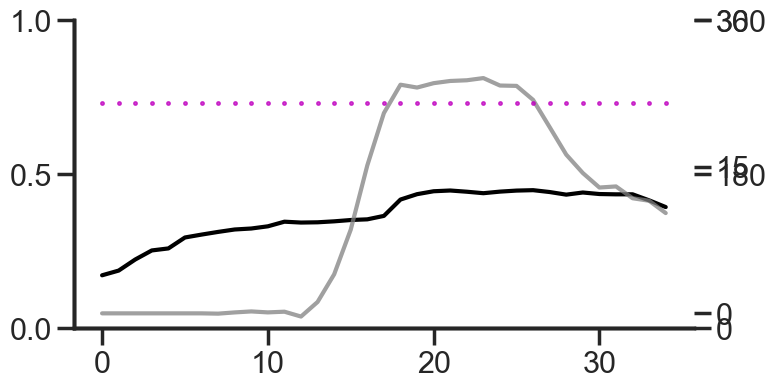

2
0.244 -0.9
3
0.024 -1.7


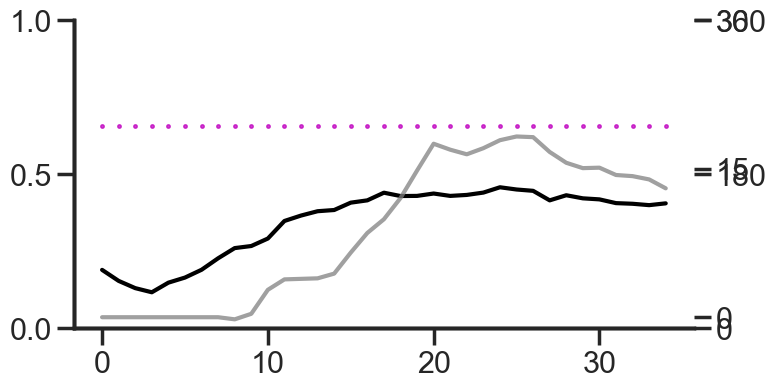

4
0.0 -0.8


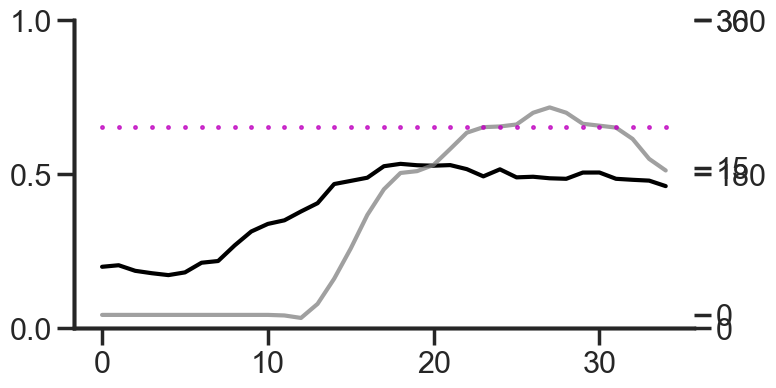

5
0.002 -0.4


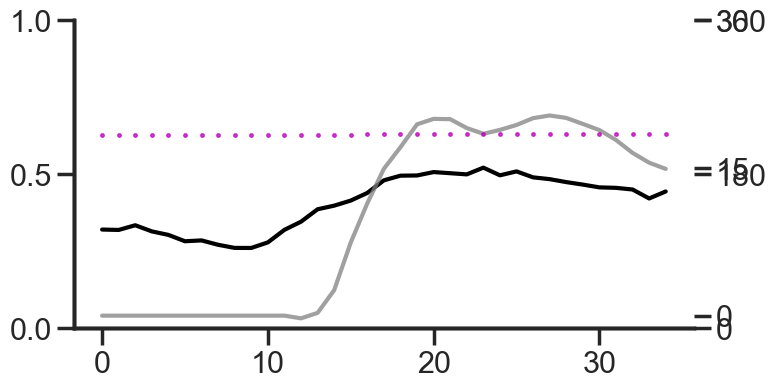

6
0.126 -0.3
7
0.004 -0.2


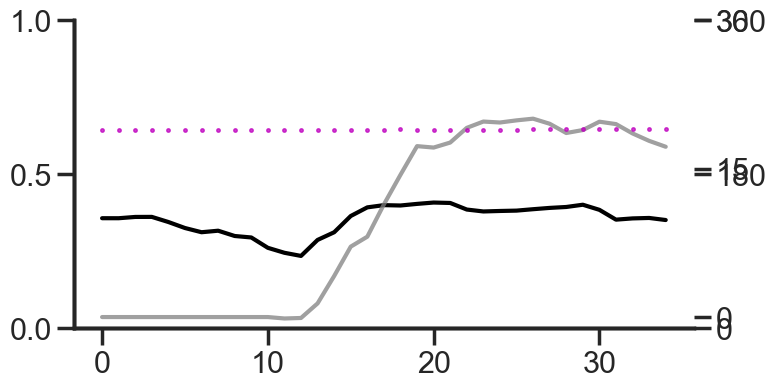

8
0.034 0.1


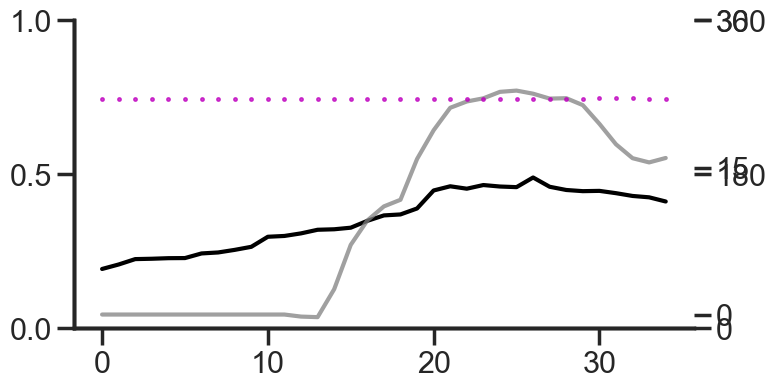

9
0.192 0.1
10
0.0 -0.5


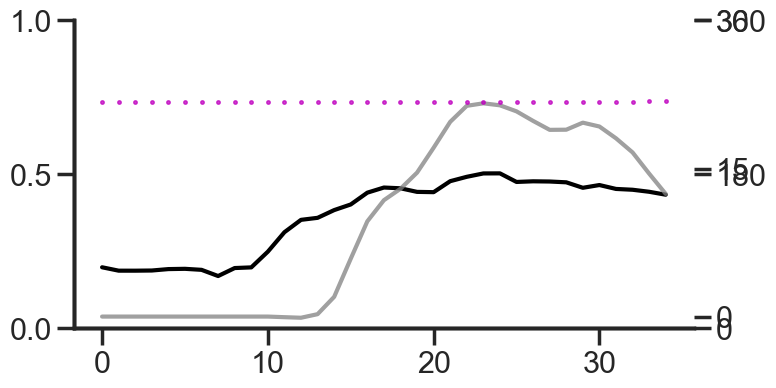

11
0.002 -0.6


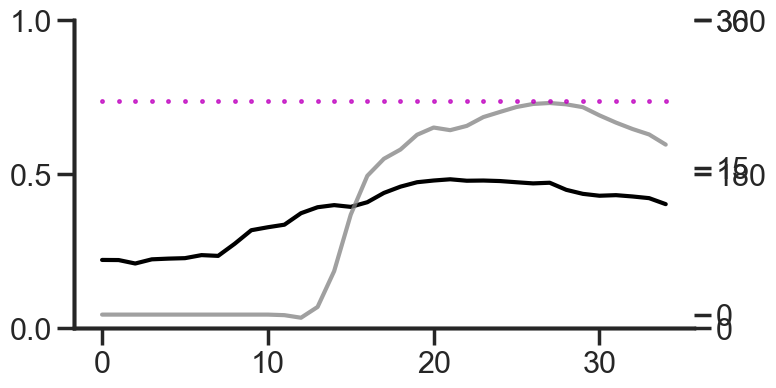

12
0.056 0.5
13
0.108 -0.8
20220819_JA180_lADN_red_H2_VR1_TS7-HF
20220809_JA181_lADN_red_H2_VR1_TS7-HF
0
0.022 -1.1


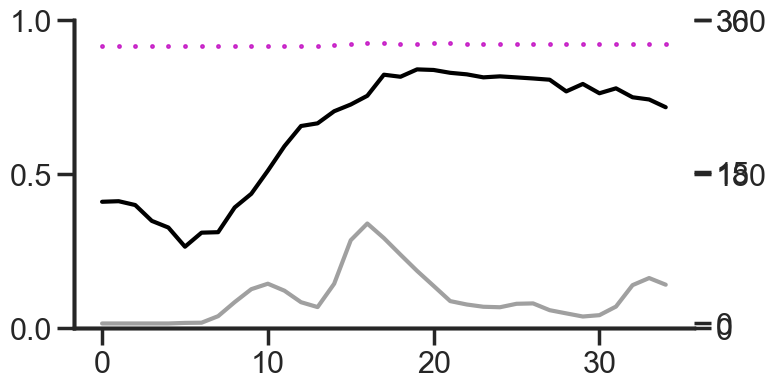

20220812_JA181_lADN_red_H2_VR1_TS7-HF
0
0.014 -1.5


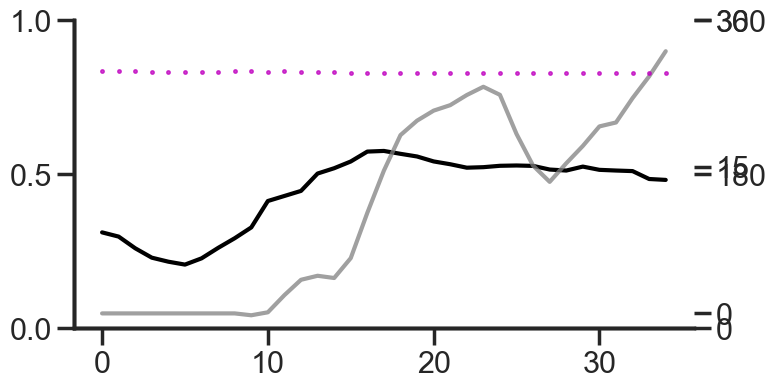

1
0.06 -0.5
20220627_MC022_lADN_red_H2_VR1_TS7-HF
0
0.514 -0.6
1
0.49 0.1
2
0.406 0.4
20220629_MC022_lADN_red_H2_VR1_TS7-HF
0
0.222 1.1
1
0.152 -2.3
2
0.0 -0.5


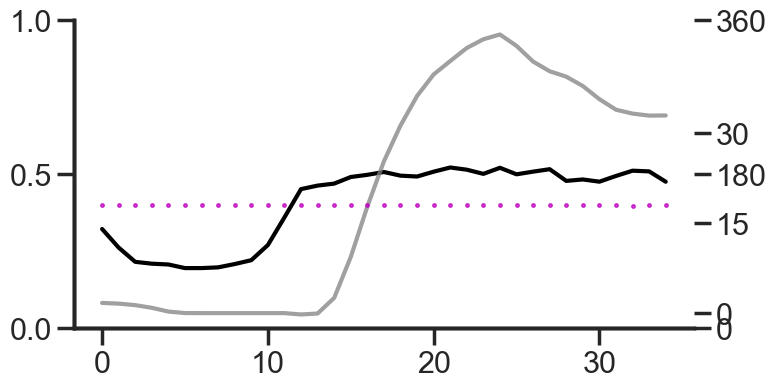

20220829_MC038_lADN_red_H2_VR1_TS7-HF
0
0.63 -2.3
1
0.11 0.1


,rec_id,epoch,aligned_speed,lag_s,xcorr_pval,lag,aligned_yaw,aligned_radius,time_idx
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,1,0.0,-0.5,0.004,-0.5,287.430167,0.218915,0
1,20220819_JA178_lADN_red_H2_VR1_TS7-HF,1,0.0,-0.5,0.004,-0.5,287.430110,0.233290,1
2,20220819_JA178_lADN_red_H2_VR1_TS7-HF,1,0.0,-0.5,0.004,-0.5,287.454461,0.256675,2
3,20220819_JA178_lADN_red_H2_VR1_TS7-HF,1,0.0,-0.5,0.004,-0.5,287.368597,0.264963,3
4,20220819_JA178_lADN_red_H2_VR1_TS7-HF,1,0.0,-0.5,0.004,-0.5,287.280151,0.264058,4


In [15]:
ls_lag = []
ls_df = []
time_idx = np.arange(35)
for k in d_run_onset.keys():
    print (k)
    aligned_speed = d_run_onset[k]['aligned_speed']
    aligned_yaw = d_run_onset[k]['aligned_yaw']
    aligned_radius = d_run_onset[k]['aligned_radius']
    if aligned_speed.shape[0] < 1:
        continue
    
    for idx, val in enumerate(aligned_speed[:]):
        print(idx)
        speed_diff = np.diff(aligned_speed[idx])
        radius_diff = np.diff(aligned_radius[idx])
        is_significant, p_value, lag_seconds = test_xcorr_significance(radius_diff, speed_diff, n_shuffles=500, fs=10, to_plot = False)
        # is_significant, p_value, lag_seconds = test_xcorr_significance(aligned_radius[idx], aligned_speed[idx], n_shuffles=500, fs=10, to_plot = False)
        print(p_value, lag_seconds)
        if p_value > 0.05:
            continue
            
        f, ax = plt.subplots(1, figsize = (8, 4))
        ax.plot(aligned_radius[idx], color = 'k',)
        ax.set_yticks([0, 0.5, 1])
        ax_1 = ax.twinx()
        ax_1.plot( aligned_speed[idx],  color = 'gray', label = 'lin speed', alpha = 0.75)
        ax_1.set_yticks([0, 15, 30])
        ax_2 = ax.twinx()
        ax_2.plot( aligned_yaw[idx], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
        ax_2.set_yticks([0, 180, 360])
        plt.show()
        
        ls_lag.append(lag_seconds)
        tmp_df = pd.DataFrame({'rec_id': k, 'epoch': idx, 'aligned_speed': aligned_speed[idx], 'lag_s':lag_seconds, 'xcorr_pval': p_value, 'lag': lag_seconds,
                              'aligned_yaw': aligned_yaw[idx], 'aligned_radius': aligned_radius[idx], 'time_idx':time_idx,
                              })
        ls_df.append(tmp_df)
    # break
df_run_onset = pd.concat(ls_df)
df_run_onset.head()

In [223]:
lag_arr.min()

-1.1322131239447322

### Using sigmoid fit

In [15]:
from scipy.optimize import curve_fit
def sigmoid(t, t0, k, base, amplitude):
    """
    Logistic sigmoid.
    t0        : midpoint / inflection point (seconds)
    k         : steepness (s^-1)
    base      : value before rise
    amplitude : total rise
    """
    return base + amplitude / (1 + np.exp(-k * (t - t0)))


def fit_sigmoid(t, signal, p0=None):
    """Fit sigmoid and return (params, covariance, fitted_curve)."""
    if p0 is None:
        t0_guess = t[len(t) // 2]
        k_guess = 3.0
        base_guess = signal[:5].mean()
        amp_guess = signal[-5:].mean() - base_guess
        p0 = [t0_guess, k_guess, base_guess, amp_guess]
    try:
        popt, pcov = curve_fit(sigmoid, t, signal, p0=p0,
                               maxfev=10000,
                               bounds=([-np.inf, 0.1, -np.inf, -np.inf],
                                       [np.inf, 50, np.inf, np.inf]))
        fitted = sigmoid(t, *popt)
        return popt, pcov, fitted
    except RuntimeError:
        print("  WARNING: sigmoid fit did not converge.")
        return None, None, np.full_like(signal, np.nan)



In [16]:
def is_good_epoch(t, signal, popt, pcov, fit, label=''):
    perr = np.sqrt(np.diag(pcov))
    
    # 1. Parameter uncertainty on t0 (your proposed criterion)
    t0_err_ok = perr[0] < 0.4          # t0 uncertain by less than 300 ms
    
    # 2. t0 must be within the time window (catch runaway fits)
    t0_in_window = t[0] < popt[0] < t[-1]
    
    # 3. Amplitude must be in the right direction and meaningful
    amp_ok = popt[3] > 0               # signal rises, not falls
    
    # 4. Goodness of fit: R²
    ss_res = np.sum((signal - fit)**2)
    ss_tot = np.sum((signal - signal.mean())**2)
    r2 = 1 - ss_res / ss_tot
    r2_ok = r2 > 0.4
    
    # 5. Steepness sanity (not a cliff, not flat)
    k_ok = 0.5 < popt[1] < 50
    
    passed = t0_err_ok and t0_in_window and amp_ok and r2_ok and k_ok
    return passed, {'perr_t0': perr[0], 'r2': r2, 'k': popt[1], 
                    't0': popt[0], 'amp': popt[3]}

In [17]:
df_stat2run.rec_id.unique()

array(['20220802_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220804_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220805_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220809_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220810_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220811_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220809_JA181_lADN_red_H2_VR1_TS7-HF',
       '20220812_JA181_lADN_red_H2_VR1_TS7-HF',
       '20220627_MC022_lADN_red_H2_VR1_TS7-HF',
       '20220629_MC022_lADN_red_H2_VR1_TS7-HF',
       '20220829_MC038_lADN_red_H2_VR1_TS7-HF'], dtype=object)

JA180_20220811_339
good epoch (True, {'perr_t0': 0.05422073717849265, 'r2': 0.949834804958553, 'k': 4.43335335734821, 't0': 0.2751364468742837, 'amp': 20.416059852217746}) (True, {'perr_t0': 0.0522350635141852, 'r2': 0.9695696730062631, 'k': 3.6354573100612866, 't0': -0.6392649641442363, 'amp': 0.43737055131863384})
Speed  sigmoid midpoint  t0 = +0.275 s  (±0.054)
Radius sigmoid midpoint  t0 = -0.639 s  (±0.052)
Estimated lag (radius - speed): -739.3 ms


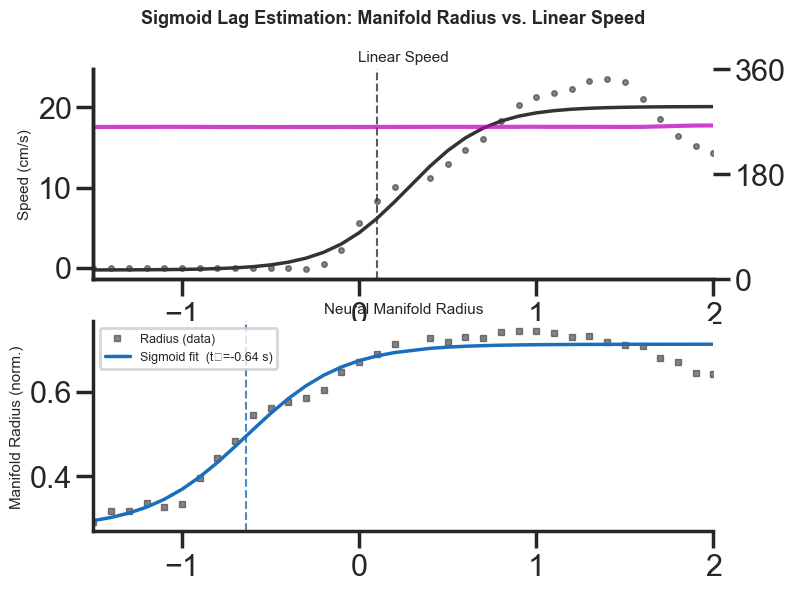

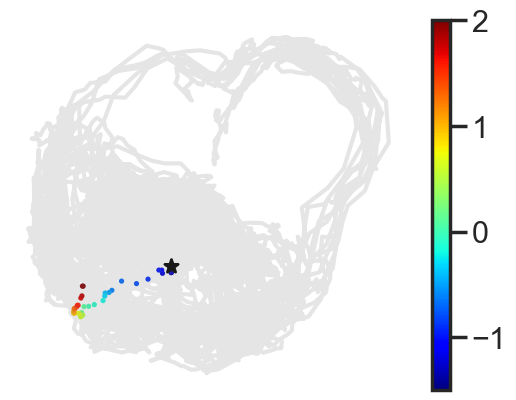

In [19]:
ls_lag = []
ls_df = []
time_idx = np.arange(35)
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1)
to_plot = True
for epid in df_stat2run.epoch_id.unique():
    if epid != 'JA180_20220811_339':
        continue
        
    print (epid)
    tmp_stat2run = df_stat2run[df_stat2run.epoch_id == epid]
    speed = tmp_stat2run['epoch_speed']
    ep_yaw = tmp_stat2run['epoch_yaw']
    radius = tmp_stat2run['epoch_ring_rad']
    ep_emb_x = tmp_stat2run['epoch_emb_x']
    ep_emb_y = tmp_stat2run['epoch_emb_y']
    rec_id = tmp_stat2run['rec_id'][0]
    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == rec_id)]
    emb_x, emb_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    

    p0_speed  = [0.0,  15.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
    p0_radius = [-0.5, 1.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
    
    popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
    popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
    
    t0_speed  = popt_s[0] if popt_s is not None else np.nan
    t0_radius = popt_r[0] if popt_r is not None else np.nan
    
    if abs(t0_speed) > 1 or abs(t0_radius) > 1:
        print(f't0 beyond limits, bad fitting')
        continue
    perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
    perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4
    
    try:
        stat2run_idx = np.where(fit_s > 5)[0][0]
        stat2run_t = t[stat2run_idx]
        base_fit_s = fit_s[:stat2run_idx].mean()
    except:
        print('bad fit')
        continue
        
    lag = t0_radius - stat2run_t   # negative → radius leads speed

    if fit_s[:10].mean() > 1:
        print('base fit_s speed > 1 cm/s')
        continue
    is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
    is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

    if is_good_speed[0] & is_good_rad[0]:
        print(f'good epoch {is_good_speed} {is_good_rad}')
    else:
        print(f'bad epoch {is_good_speed} {is_good_rad}')
        continue

    
    print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
    print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
    print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
    
    if to_plot == True:
        fig, axes = plt.subplots(2, 1, figsize=(8, 6))
        fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                     fontsize=13, fontweight='bold', y=0.98)
                
        # --- Panel 1: Speed ---
        ax = axes[0]
        ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
        ax.plot(t, fit_s, '-', color='#333333', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
        ax.axvline(stat2run_t, color='#333333', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Speed (cm/s)', fontsize=11)
        # ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Linear Speed', fontsize=11)
        # ax.grid(True, alpha=0.3)
        ax_2 = ax.twinx()
        ax_2.plot(t, ep_yaw, 'm', label = 'yaw', alpha = 0.75)
        ax_2.set_yticks([0, 180, 360])
        
        # --- Panel 2: Radius ---
        ax = axes[1]
        ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
        ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
        ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
        ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Neural Manifold Radius', fontsize=11)
        # ax.grid(True, alpha=0.3)
        # filepath = save_dir / f'line_{epid}_vel_rad.pdf'
        # plt.savefig(filepath, transparent = True)
    
        ls_lag.append(lag)
    
        # f, ax = plt.subplots(1, figsize = (8, 4))
        # ax.plot(radius, color = 'k',)
        # ax.set_yticks([0, 0.5, 1])
        # # ax_1 = ax.twinx()
        # # ax_1.plot( speed,  color = 'gray', label = 'lin speed', alpha = 0.75)
        # # ax_1.set_yticks([0, 15, 30])
        # ax_2 = ax.twinx()
        # ax_2.plot( ep_yaw, 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
        # ax_2.set_yticks([0, 180, 360])
        # sns.despine(offset = 10, trim = True)
        # # plt.savefig(f'line_vel_{k}_{ep_idx}.pdf', transparent = True)
        # time.sleep(0.2)
        
        f, ax = plt.subplots()
        plt.scatter(ep_emb_x[:], ep_emb_y[:], alpha = 1, s = 3,  c = t, 
                    cmap = 'jet')
        plt.colorbar()
        plt.plot(emb_x[:], emb_y[:], c = 'gray', alpha = 0.2)
        plt.scatter(ep_emb_x[0], ep_emb_y[0], c = 'k', s = 100, marker = "*")
        plt.axis('off')
        
        # filepath = save_dir / f'scatter-vr_{epid}_vel_rad.pdf'
        # plt.savefig(filepath, transparent = True)
    
        plt.show()
    

    break
#     tmp_df = pd.DataFrame({'rec_id': k, 'epoch': epid, 'ep_speed': speed, 'lag_s':lag, 'ep_emb_x': ep_emb_x, 'ep_emb_y':ep_emb_y,
#                           'ep_yaw': ep_yaw, 'ep_radius': radius, 'time_s':t, 'speed_onset':stat2run_t, 'rad_onset':t0_radius, 'fit_s': fit_s, 'fit_r': fit_r,
#                           })
#     ls_df.append(tmp_df)

# df_run_onset = pd.concat(ls_df)
# df_run_onset.head()

In [21]:
# filepath = save_dir / f'out.xlsx'
# pd.DataFrame({'ep_emb_x': ep_emb_x, 'ep_emb_y': ep_emb_y, 'speed': speed, 'fit_s': fit_s, 't':t, 
#               'radius': radius, 'fit_r': fit_r, 'ep_yaw': ep_yaw}).to_excel(filepath, index = True)

In [20]:
df_run_onset['epoch'].unique().size

30

In [21]:
# fig = plt.figure(figsize=(8, 8))
# ax = fig.add_subplot(111, projection='3d')
# time_values_full = np.arange(emb_x[:].size)
# # Plot with time as z-axis

# ax.scatter(time_values_full, emb_x[:], emb_y[:], 
#                     c= lin_speed_sess[:], vmin = 0, vmax = 25, cmap='plasma', s=5, alpha=0.5)
# # ax.scatter(t_idx, ep_emb_x.values[:], ep_emb_y.values[:], 
# #                     c = t_idx, cmap='jet', s=30, alpha=0.8)
# ax.view_init(elev=30, azim=-60) 
# # plt.show()
# # ax.axis('off')

# of epochs 30
mean -0.49872782317129616 -0.9970058372839283 0.09313799509686747
sem 0.04725977665974514


(-1.5, 1.5)

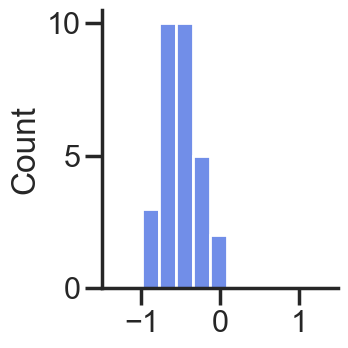

In [22]:
lag_arr = df_run_onset.loc[0]['lag_s'].values
sns.displot(lag_arr, bins = 5,  height=4, aspect = 1, color = 'royalblue')
print('# of epochs', len(lag_arr))
print('mean', np.mean(lag_arr), lag_arr.min(), lag_arr.max())
print('sem', stats.sem(lag_arr))

plt.xlim(-1.5, 1.5)

# filepath = save_dir / 'dist_vr_lag-rad_vel.pdf'
# plt.savefig(filepath, transparent = True)

In [95]:
# pd.DataFrame(lag_arr).to_excel(filepath, index = True)

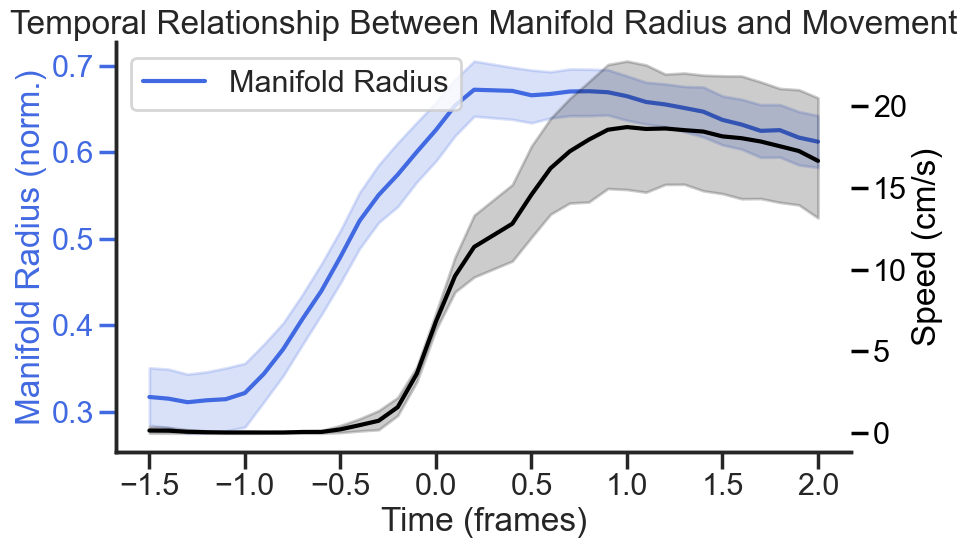

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 6))
_inp = df_run_onset
# Plot radius data on primary axis
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_radius',
    ax=ax1,
    color='royalblue',
    label='Manifold Radius'
)
ax1.set_xlabel('Time (frames)')
ax1.set_ylabel('Manifold Radius (norm.)', color='royalblue')
ax1.tick_params(axis='y', colors='royalblue')

# Add a secondary y-axis for speed
ax2 = ax1.twinx()
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_speed',
    ax=ax2,
    color='k',
    # label='Speed'
)
ax2.set_ylabel('Speed (cm/s)', color='k')
ax2.tick_params(axis='y', colors='k')

# Add vertical line at t=0 (movement onset)
# ax1.axvline(x=15, color='black', linestyle='--', label='Movement Onset')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Temporal Relationship Between Manifold Radius and Movement')
plt.tight_layout()

# filepath = save_dir / 'line-vr_vel_rad.pdf'
# plt.savefig(filepath, transparent = True)

In [92]:
filepath = save_dir / f'out.xlsx'
# _inp_plot['cond'] = _inp_plot['cond'].replace({'L1': 'RL', 'TS7-HF': 'VR-YawFree'})
_inp.to_excel(filepath, index = True)


,rec_id,epoch,ep_speed,lag_s,ep_emb_x,ep_emb_y,ep_yaw,ep_radius,time_s,speed_onset,rad_onset,fit_s,fit_r
0,20220830_MC038_lADN_red_H2_VR1_TS6-HF,JA179_20220802_4856,0.000000,-0.634391,6.551869,-7.215268,53.637816,0.381106,-1.5,0.0,-0.634391,0.255682,0.411447
1,20220830_MC038_lADN_red_H2_VR1_TS6-HF,JA179_20220802_4856,0.000000,-0.634391,6.810913,-8.360899,53.554116,0.418789,-1.4,0.0,-0.634391,0.255878,0.411447
2,20220830_MC038_lADN_red_H2_VR1_TS6-HF,JA179_20220802_4856,0.000000,-0.634391,6.788127,-8.070040,53.563475,0.408994,-1.3,0.0,-0.634391,0.256333,0.411447
3,20220830_MC038_lADN_red_H2_VR1_TS6-HF,JA179_20220802_4856,0.000000,-0.634391,6.912098,-8.111912,53.674933,0.409921,-1.2,0.0,-0.634391,0.257391,0.411447
4,20220830_MC038_lADN_red_H2_VR1_TS6-HF,JA179_20220802_4856,0.000000,-0.634391,6.894665,-8.213193,53.669390,0.413435,-1.1,0.0,-0.634391,0.259850,0.411447
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,20220830_MC038_lADN_red_H2_VR1_TS6-HF,MC038_20220829_8208,8.428255,-0.370487,-11.543314,-11.104163,237.444361,0.633640,1.6,0.0,-0.370487,8.263682,0.648864
31,20220830_MC038_lADN_red_H2_VR1_TS6-HF,MC038_20220829_8208,5.352533,-0.370487,-10.508388,-11.242003,237.826357,0.611887,1.7,0.0,-0.370487,8.263682,0.648869
32,20220830_MC038_lADN_red_H2_VR1_TS6-HF,MC038_20220829_8208,2.965016,-0.370487,-10.435162,-11.282864,237.566890,0.611216,1.8,0.0,-0.370487,8.263682,0.648872
33,20220830_MC038_lADN_red_H2_VR1_TS6-HF,MC038_20220829_8208,2.447038,-0.370487,-8.985803,-12.229364,237.497450,0.604696,1.9,0.0,-0.370487,8.263682,0.648874


0.0 -0.5


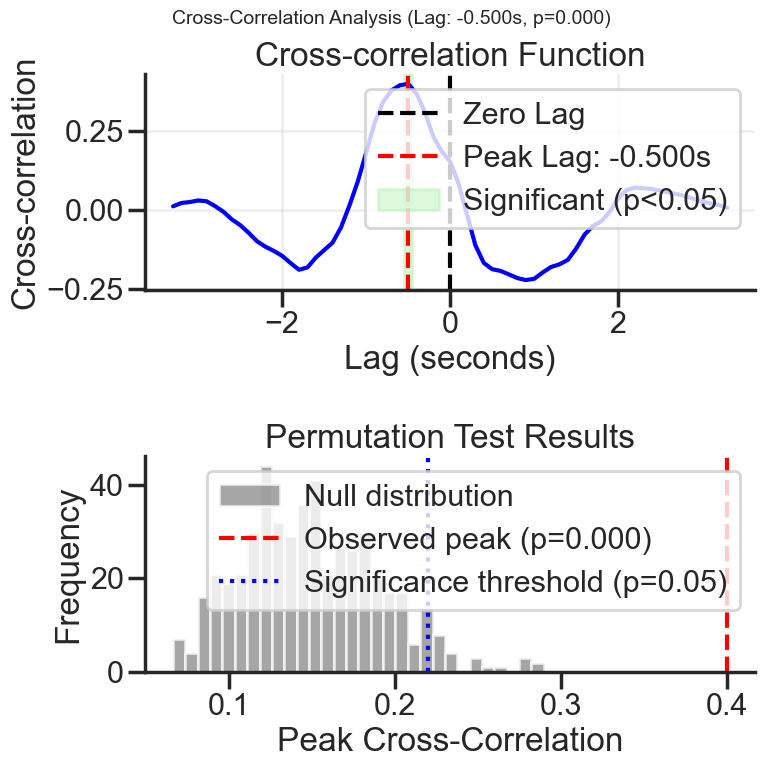

In [24]:
a = df_run_onset.groupby([ 'time_s'])['ep_speed'].mean()
b = df_run_onset.groupby([ 'time_s'])['ep_radius'].mean()
speed_diff = np.diff(a.values)
radius_diff = np.diff(b.values)
is_significant, p_value, lag_seconds = test_xcorr_significance(radius_diff, speed_diff, n_shuffles=500, fs=10, to_plot = True)
print(p_value, lag_seconds)
# plt.savefig(f'xcorr-vr_meanvel_rad.pdf', transparent = True)

## Fig 4C-D: HD manifold during stat, run, rot

20220819_JA178_lADN_red_H2_VR1_TS7-HF
20220823_JA178_lADN_red_H2_VR1_TS7-HF
20220907_JA178_rADN_yel_H2_VR1_TS7-HF
20220802_JA179_lADN_red_H2_VR1_TS7-HF
20220804_JA179_lADN_red_H2_VR1_TS7-HF
20220805_JA179_lADN_red_H2_VR1_TS7-HF
20220809_JA180_lADN_red_H2_VR1_TS7-HF
20220810_JA180_lADN_red_H2_VR1_TS7-HF
stat_norot


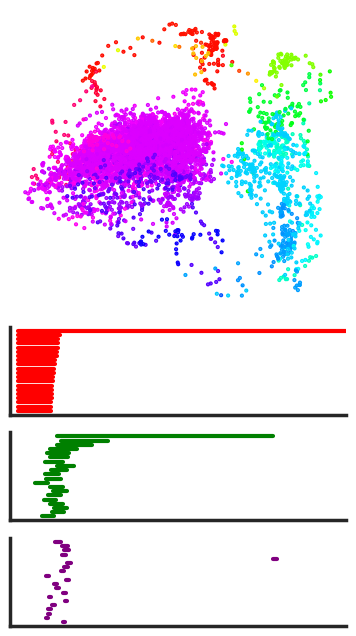

run_norot


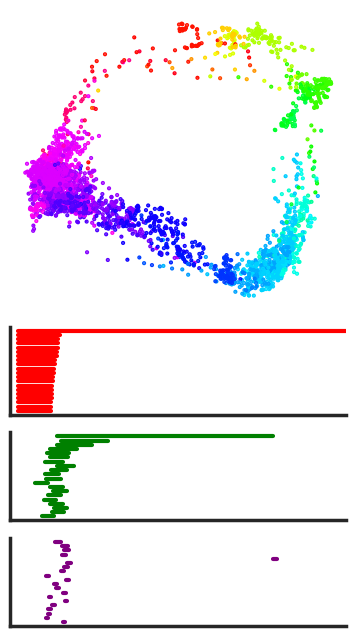

stat_rot


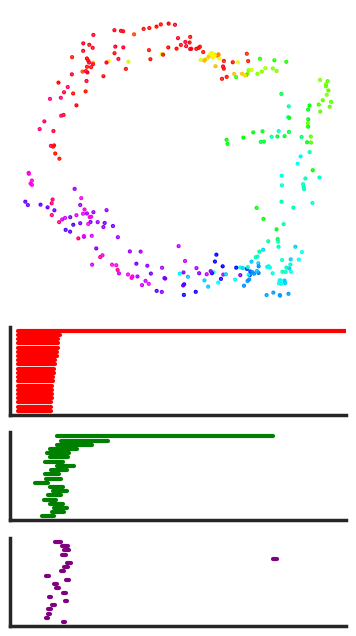

run_rot


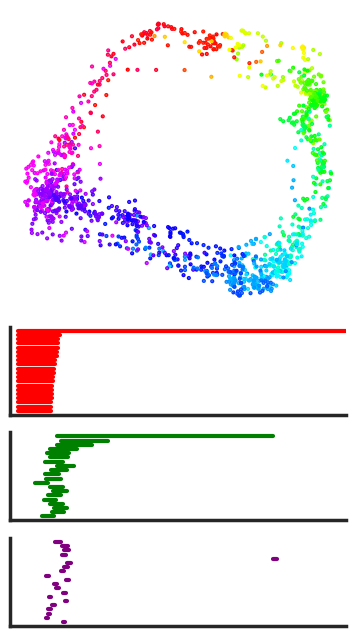

20220811_JA180_lADN_red_H2_VR1_TS7-HF
20220819_JA180_lADN_red_H2_VR1_TS7-HF
20220809_JA181_lADN_red_H2_VR1_TS7-HF
20220812_JA181_lADN_red_H2_VR1_TS7-HF
20220627_MC022_lADN_red_H2_VR1_TS7-HF
20220629_MC022_lADN_red_H2_VR1_TS7-HF
20220829_MC038_lADN_red_H2_VR1_TS7-HF


In [76]:
ls_df = []
ls_beh_cond = ['stat_norot', 'run_norot', 'stat_rot',  'run_rot']
col_list = ['red', 'green', 'purple']
angles = np.arange(0, 380, 20)

for k in d_emb_ang.keys():
    if 'TS7-HF' not in k:
        continue
    print(k)
    if k != '20220810_JA180_lADN_red_H2_VR1_TS7-HF':
        continue
    dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
    rec_session = mouse_id + '_' + dts
    
    
    tmp = d_emb_ang[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    isomap_yaw = tmp['isomap_yaw']
    lin_speed = tmp['lin_speed']
    run_rot = tmp['run_rot']['idx']
    # compute off manifold ratios
    _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    offmanifold_threshold = np.percentile(rad_manifold[run_rot], 10)
    
    # fig = plt.figure(figsize=(6, 6))
    for idx, run_cond in enumerate(ls_beh_cond[:]):
        print(run_cond)
        cond_idx = d_emb_ang[k][run_cond]['idx']
        dec_err = d_emb_ang[k][run_cond]['dec_err']
        omi = np.sum(rad_manifold[cond_idx] < offmanifold_threshold)/rad_manifold[cond_idx].size 
        h0 = d_emb_ang[k][run_cond]['h0']
        h1 = d_emb_ang[k][run_cond]['h1']
        h2 = d_emb_ang[k][run_cond]['h2']

        # h0 = np.ndarray.flatten(to_plot[0])
        # h1 = np.ndarray.flatten(to_plot[1])
        # h2 = np.ndarray.flatten(to_plot[2])
        # filepath = save_dir / f'{run_cond}_out.xlsx'
        # pd.DataFrame({'h0': h0, 'h1':h1, 'h2':h2}).to_excel(filepath, index = True)
        
        # h1bar = sorted(h1[:, 1] - h1[:, 0])[-1]
        # cond_ratio = round(cond_idx.size/lin_speed.size, 3)
        # occup, _ = np.histogram(measured_yaw[cond_idx], bins = angles)
        # at least 1s
        cond_az_occ = occup[occup > 10].size/occup.size
        # print(run_cond, omi)
        
#         try:
# #             h1bar = d_emb_ang[k][run_cond]['h1bar']
#             to_plot, _ = get_long_bettibars(h0, h1, h2)
#         except:
#             print('not')
#             continue

        # tmp_df = pd.DataFrame({'rec_id': k, 'cond': cond, 'dts': dts, 'mouse_id': mouse_id, 'omi':omi,
        #                'cond_az_occ':cond_az_occ, 'run_cond': run_cond, 'h1bar': h1bar, 'dec_err': dec_err, 
        #                'rec_session':rec_session, 'cond_ratio': cond_ratio}, index = [0])
        # ls_df.append(tmp_df)

        fig = plt.figure(figsize=(12, 8))
        gs = gridspec.GridSpec(6, 8)
        ax = fig.add_subplot(gs[0:3, 0:3])
        ax.scatter(isomap[cond_idx, 0], isomap[cond_idx, 1], s = 1, c = measured_yaw[cond_idx], 
                                               vmin = 0, vmax = 360, cmap = 'hsv')
        ax.axis('off')
        plt.xticks([])
        
        # filepath = save_dir / f'{run_cond}_emb.xlsx'
        # pd.DataFrame({'isomap_x': isomap[cond_idx,0], 'isomap_y':isomap[cond_idx,1], 'yaw': measured_yaw[cond_idx] }).to_excel(filepath, index = True)
        
        for curr_betti, curr_bar in enumerate(to_plot):
            ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])
            for i, interval in enumerate((curr_bar)):
                ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
            ax.set_xlim([-1, 40])
            plt.xticks([])
            plt.yticks([])
        plt.show()
        
        plt.show()
        
    # break
# df_emb_ang = pd.concat(ls_df)
# df_emb_ang.head()

C:\Users\01\anaconda3\envs\py39\lib\site-packages\seaborn\categorical.py:3399: UserWarning: 40.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='run_cond', ylabel='omi'>

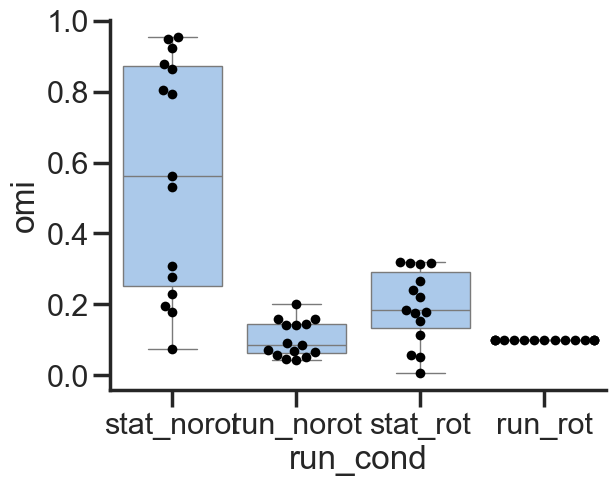

In [85]:
_inp_plot = df_emb_ang[(df_emb_ang.cond == 'TS7-HF')]
y = 'omi'
ls_beh_cond = ['stat_norot', 'run_norot', 'stat_rot',  'run_rot']

sns.boxplot(data = _inp_plot, x = 'run_cond', y = y, order = ls_beh_cond)
sns.swarmplot(data = _inp_plot, x = 'run_cond', y = y, size = 7, color = 'k', dodge = True, legend = False)

# plt.savefig(f'boxplot_{y}_lin-ang_vel.pdf', transparent = True)

In [86]:
_inp_plot.groupby('run_cond')[y].describe()

,count,mean,std,min,25%,50%,75%,max
run_cond,,,,,,,,
run_norot,15.0,0.102010,0.050933,0.043121,0.061779,0.085541,0.144158,0.201471
run_rot,15.0,0.100303,0.000277,0.100000,0.100000,0.100315,0.100490,0.100752
stat_norot,15.0,0.568194,0.328789,0.073973,0.253222,0.560879,0.871382,0.953791
stat_rot,15.0,0.194383,0.103961,0.006250,0.132440,0.184615,0.290909,0.319192


In [87]:
a1 = _inp_plot[_inp_plot.run_cond == 'stat_norot'][y]
a2 = _inp_plot[_inp_plot.run_cond == 'stat_rot'][y]
a3 = _inp_plot[_inp_plot.run_cond == 'run_norot'][y]
a4 = _inp_plot[_inp_plot.run_cond == 'run_rot'][y]

print(stats.kruskal(a1, a2, a3, a4))
print('stat vs run')
print(stats.mannwhitneyu(a1, a3))

print('stat vs rot')
print(stats.mannwhitneyu(a1, a2))

print('stat vs run_rot')
print(stats.mannwhitneyu(a1, a4))

KruskalResult(statistic=28.99906588824021, pvalue=2.2404413642718297e-06)
stat vs run
MannwhitneyuResult(statistic=215.0, pvalue=2.3290004782067234e-05)
stat vs rot
MannwhitneyuResult(statistic=184.0, pvalue=0.0032301435955866646)
stat vs run_rot
MannwhitneyuResult(statistic=210.0, pvalue=5.522107927318714e-05)


In [88]:
_inp_plot.head()

,rec_id,cond,dts,mouse_id,omi,cond_az_occ,run_cond,h1bar,dec_err,rec_session,cond_ratio
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,TS7-HF,20220819,JA178,0.228049,0.500000,stat_norot,1.801161,24.911,JA178_20220819,0.307
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,TS7-HF,20220819,JA178,0.069595,0.833333,run_norot,31.456684,29.836,JA178_20220819,0.553
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,TS7-HF,20220819,JA178,0.184615,0.111111,stat_rot,1.110619,39.054,JA178_20220819,0.012
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,TS7-HF,20220819,JA178,0.100752,0.777778,run_rot,29.501816,29.225,JA178_20220819,0.124
0,20220823_JA178_lADN_red_H2_VR1_TS7-HF,TS7-HF,20220823,JA178,0.178512,0.722222,stat_norot,11.088336,22.541,JA178_20220823,0.119


In [90]:
_inp_plot.to_excel(filepath, index = True)

## Fig 4E: Test various lin and ang vel thresholds

In [81]:
col_list = ['red', 'green', 'purple']
angles = np.arange(0, 380, 20)
h1_bar_max = 40
ls = []
lin_vel_thr = [1, 2, 4, 8]
ang_vel_thr = [5, 10, 20, 40]
ls_name = ['stat_norot', 'stat_rot', 'run_norot', 'run_rot']

for k in d_emb.keys():
    if 'LMK' in k:
        continue
    if 'TS7-HF' not in k:
        continue
    for lin_t in lin_vel_thr:
        for ang_t in ang_vel_thr:
            # print(lin_t, ang_t)
            start_time = time.time()
        
            dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
            rec_session = mouse_id + '_' + dts
            tmp = d_emb[k]
            isomap = tmp['isomap']
            measured_yaw = tmp['measured_yaw']
            isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
            dyaw = compute_dYaw(measured_yaw)
            # sampling 10 Hz, 100ms
            ang_vel = dyaw*100
            lin_speed = tmp['lin_vel']
        
            # find stat, run, rot epochs
            try:
                stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = lin_t)
                _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = ang_t)
            except:
                # print(k)
                continue
        
            # Finding unique elements
            stat_norot = np.setdiff1d(stat_idx, rot_idx)
            stat_rot = np.intersect1d(stat_idx, rot_idx)
            run_norot = np.setdiff1d(run_idx, rot_idx)
            run_rot = np.intersect1d(run_idx, rot_idx)
        
            if stat_norot.size < 5:
                # print(k)
                continue
            
            stat_ratio = stat_norot.size/lin_speed.size
            stat_rot_ratio = stat_rot.size/stat_idx.size
            run_rot_ratio = run_rot.size/run_idx.size
        
            run_ratio = run_idx.size/lin_speed.size
            # 50 samples = 5s
            occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
            stat_az_occ = occup[occup > 10].size/occup.size
            occup, _ = np.histogram(measured_yaw[run_idx], bins = angles)
            run_az_occ = occup[occup > 10].size/occup.size
            # compute off manifold ratios
            _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
            _, rad_manifold_stat = compute_radius_old(isomap[stat_norot,0], isomap[stat_norot,1])
            _, rad_manifold_loc = compute_radius_old(isomap[run_rot,0], isomap[run_rot,1])
        
            offmanifold_threshold = np.percentile(rad_manifold_loc, 10)
            stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
            
            tmp_df = pd.DataFrame({'rec_id': k, 'rec_session': rec_session, 'stat_ratio': stat_ratio,
                                  'lin_thr': lin_t, 'ang_thr':ang_t, 'stat_off_manifold':stat_off_manifold}, index = [0])
            ls.append(tmp_df)
            # print(f'{k}')
        
        #     f,ax = plt.subplots(2, 2, figsize = (6, 6))
        #     ax[0][0].scatter(isomap[stat_norot,0], isomap[stat_norot,1], s = 1, c = measured_yaw[stat_norot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[0][0].axis('off')
        #     plt.xticks([])
        
        #     ax[0][1].scatter(isomap[stat_rot,0], isomap[stat_rot,1], s = 1, c = measured_yaw[stat_rot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[0][1].axis('off')
        #     plt.xticks([])
        
        #     ax[1][0].scatter(isomap[run_norot,0], isomap[run_norot,1], s = 1, c = measured_yaw[run_norot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[1][0].axis('off')
        #     plt.xticks([])
        
        #     ax[1][1].scatter(isomap[run_rot,0], isomap[run_rot,1], s = 1, c = measured_yaw[run_rot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[1][1].axis('off')
        #     plt.xticks([])
        #     plt.show()
        
            # end_time = time.time()
            # print(end_time - start_time)
        # break
    
df_vel = pd.concat(ls)
df_vel.head()

,rec_id,rec_session,stat_ratio,lin_thr,ang_thr,stat_off_manifold
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_20220819,0.199065,1,5,0.518310
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_20220819,0.238318,1,10,0.316863
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_20220819,0.241121,1,20,0.309302
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_20220819,0.242056,1,40,0.359846
0,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_20220819,0.223364,2,5,0.449372


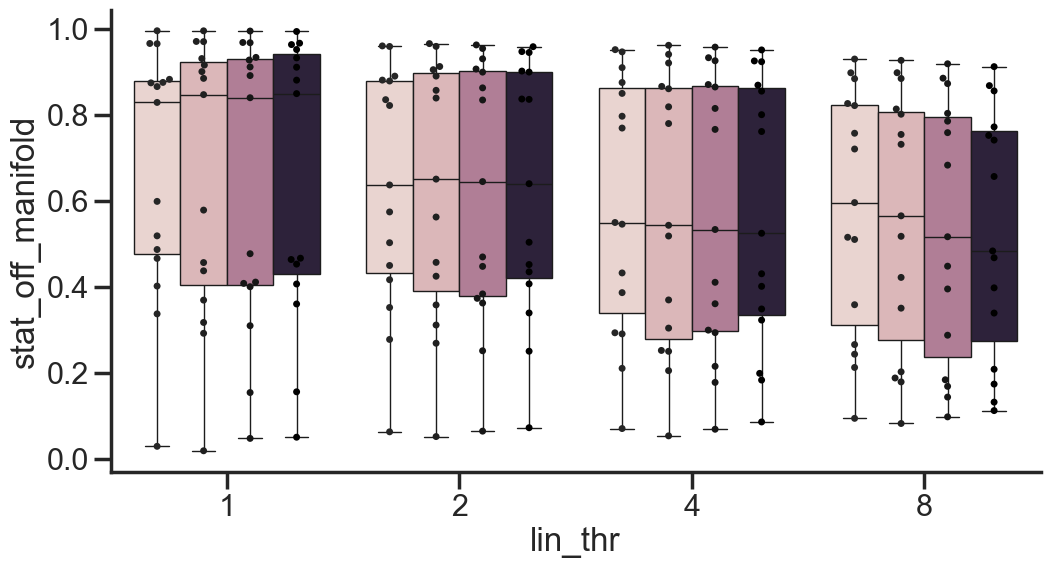

In [82]:
f, ax = plt.subplots(figsize = (12, 6))
_inp_plot = df_vel
y = 'stat_off_manifold'

sns.boxplot(data = _inp_plot, x = 'lin_thr', y = y, hue = 'ang_thr')
sns.swarmplot(data = _inp_plot, x = 'lin_thr', y = y,   hue = 'ang_thr', palette='dark:k', dodge = True, legend = False)
plt.legend().remove()  # This line removes the legend

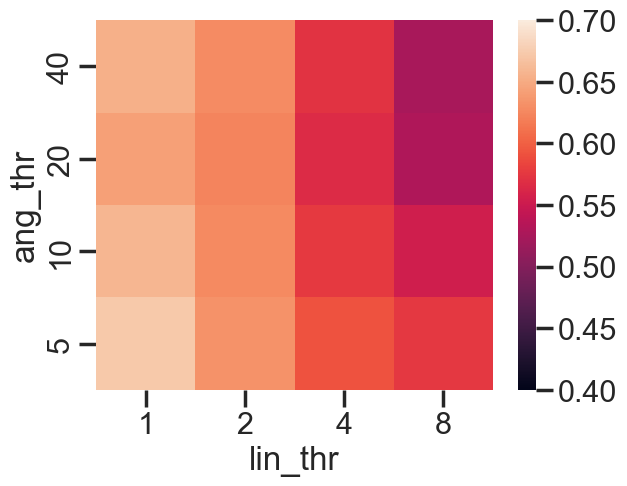

In [83]:
_inp_plot_2 = _inp_plot.groupby([ 'lin_thr', 'ang_thr'])[y].mean().reset_index()
_inp_plot_3 = _inp_plot_2.pivot(index = 'ang_thr', columns = 'lin_thr', values = 'stat_off_manifold')
ax = sns.heatmap(_inp_plot_3, vmin = 0.4, vmax  = 0.7, cmap = 'rocket')
ax.invert_yaxis()  # This line inverts the y-axis
# plt.savefig(f'hetamap_offmanifold_lin-ang_vel.png', dpi = 300, transparent = True)
# plt.savefig(f'hetamap_offmanifold_lin-ang_vel.pdf', transparent = True)

## Isomap all units vs HDC only

In [103]:
df_emb_hdc.head()

,measured_yaw,emb_x,emb_y,lin_speed,dts,mouse_id,hem,rec_session,brain_areas,cond,hstripe,rec_id,rad_manifold
0,3.0,-9.374082,-8.338740,20.351674,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.546235
1,3.0,-10.445573,-7.463811,15.996554,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.838165
2,3.0,-10.621456,-7.259102,13.689262,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.865065
3,3.0,-10.446476,-7.307741,13.451142,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.748801
4,3.0,-8.509475,-6.505912,15.446077,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,10.711585


20220804_JA179_lADN_red_H2_VR1_TS7-HF
dict_keys(['isomap', 'hdc_arena', 'measured_yaw', 'lin_vel', 'ang_vel', 'dts', 'cond', 'mouse_id', 'implant', 'rec_session', 'stat_idx', 'run_idx', 'rad_manifold', 'rad_manifold_norm', 'h0', 'h1', 'h2', 'h1_bar', 'run_ratio', 'lin_vel_thr', 'stat_az_occ', 'run_az_occ', 'stat', 'run'])


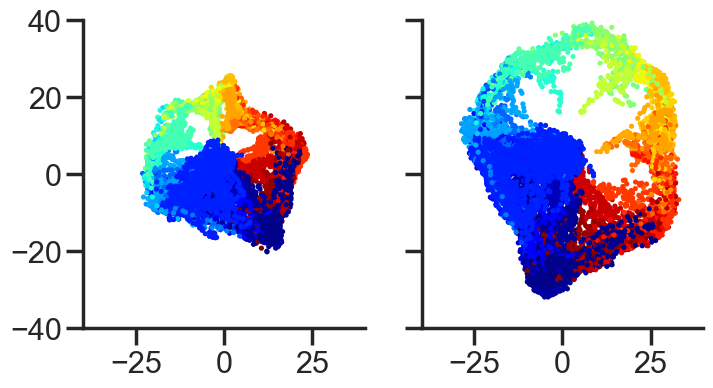

20220810_JA180_lADN_red_H2_VR1_TS7-HF
dict_keys(['isomap', 'hdc_arena', 'measured_yaw', 'lin_vel', 'ang_vel', 'dts', 'cond', 'mouse_id', 'implant', 'rec_session', 'stat_idx', 'run_idx', 'rad_manifold', 'rad_manifold_norm', 'h0', 'h1', 'h2', 'h1_bar', 'run_ratio', 'lin_vel_thr', 'stat_az_occ', 'run_az_occ', 'stat', 'run'])


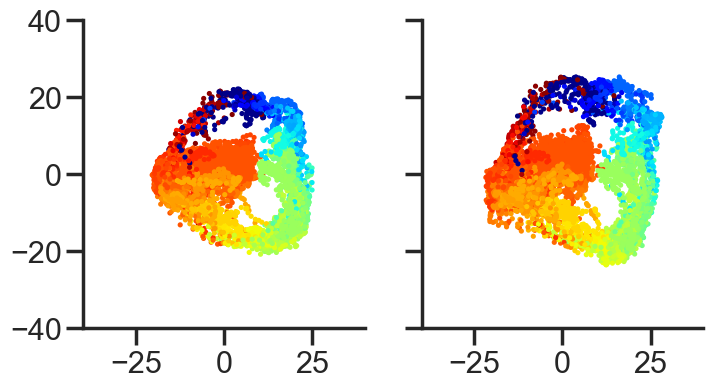

20220812_JA181_lADN_red_H2_VR1_TS7-HF
dict_keys(['isomap', 'hdc_arena', 'measured_yaw', 'lin_vel', 'ang_vel', 'dts', 'cond', 'mouse_id', 'implant', 'rec_session', 'stat_idx', 'run_idx', 'rad_manifold', 'rad_manifold_norm', 'h0', 'h1', 'h2', 'h1_bar', 'run_ratio', 'lin_vel_thr', 'stat_az_occ', 'run_az_occ', 'stat', 'run'])


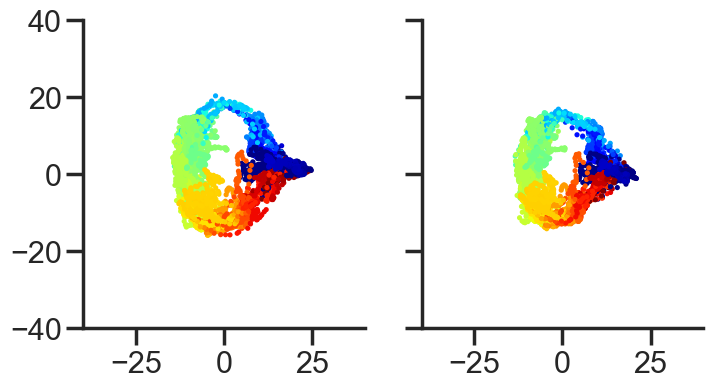

20220829_MC038_lADN_red_H2_VR1_TS7-HF
dict_keys(['isomap', 'hdc_arena', 'measured_yaw', 'lin_vel', 'ang_vel', 'dts', 'cond', 'mouse_id', 'implant', 'rec_session', 'stat_idx', 'run_idx', 'rad_manifold', 'rad_manifold_norm', 'h0', 'h1', 'h2', 'h1_bar', 'run_ratio', 'lin_vel_thr', 'stat_az_occ', 'run_az_occ', 'stat', 'run'])


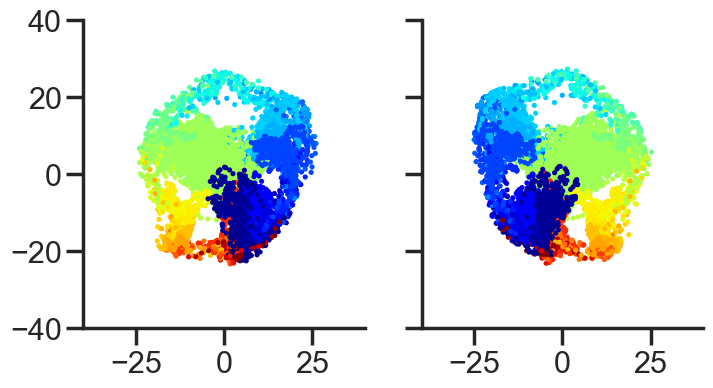

In [107]:
speed_threshold = 5
roi = ['20220804_JA179_lADN_red_H2_VR1_TS7-HF', '20220810_JA180_lADN_red_H2_VR1_TS7-HF', '20220812_JA181_lADN_red_H2_VR1_TS7-HF', '20220829_MC038_lADN_red_H2_VR1_TS7-HF']
ls = []

for k in df_emb_hdc.rec_id.unique():
    if k not in roi:
        continue
    print(k)
    print(d_emb[k].keys())

    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    emb_hdc_x, emb_hdc_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    
    lin_speed = tmp_df['lin_speed'].values
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = speed_threshold)
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True
    cxy, rad_manifold = compute_radius(emb_hdc_x, emb_hdc_y, run_mask)
    # get stat epochs
    # stat_epoch = consecutive(stat_idx)

    measured_yaw = tmp_df['measured_yaw'].values[:]
    # measured_yaw_rad = np.deg2rad(measured_yaw)

    emb_x = d_emb[k]['isomap'][:, 0]
    emb_y = d_emb[k]['isomap'][:, 1]

    ls.append(pd.DataFrame({'rec':k.split('_')[1], 'emb_x': emb_x, 'emb_y':emb_y, 'emb_hdc_x':emb_hdc_x, 'emb_hdc_y': emb_hdc_y, 'yaw': measured_yaw }))
    
    f, ax = plt.subplots(1, 2, figsize = (8, 4), sharex = True, sharey = True)
    ax[0].scatter(emb_hdc_x[:], emb_hdc_y[:], alpha = 1, s = 3,  c = measured_yaw, 
            cmap = 'jet')
    
    ax[1].scatter(emb_x[:], emb_y[:], alpha = 1, s = 3,  c = measured_yaw, 
            cmap = 'jet')
    # f.colorbar(ax[1])
    ax[1].set_xlim(-40, 40)
    ax[1].set_ylim(-40, 40)

    plt.show()
    # break

In [108]:
df_out = pd.concat(ls)
df_out.head()

,rec,emb_x,emb_y,emb_hdc_x,emb_hdc_y,yaw
0,JA179,-10.633378,3.199544,-7.139375,-4.336528,60.618695
1,JA179,-12.371025,3.325760,-8.173151,-5.706704,60.611454
2,JA179,-14.451818,3.695815,-9.092638,-5.998629,60.619036
3,JA179,-16.082619,3.375602,-9.857594,-6.848775,60.641443
4,JA179,-17.860823,3.097795,-10.979734,-8.242963,60.684208


In [109]:
df_out.to_excel(filepath, index = True)

### Isomap first vs second half of rec

20220819_JA178_lADN_red_H2_VR1_TS7-HF


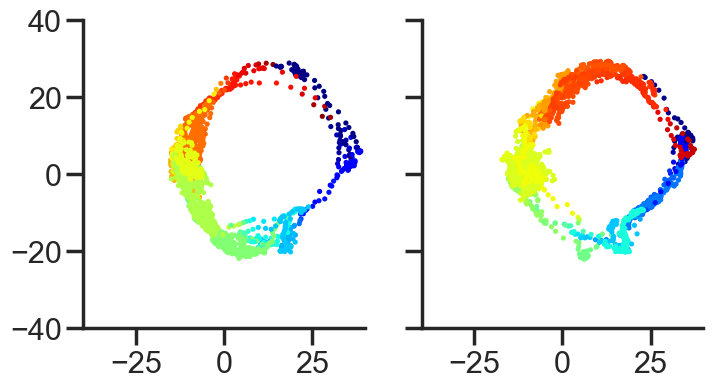

20220823_JA178_lADN_red_H2_VR1_TS7-HF


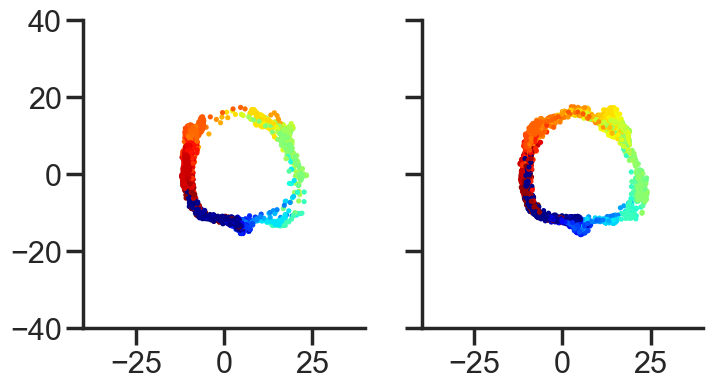

20220907_JA178_rADN_yel_H2_VR1_TS7-HF


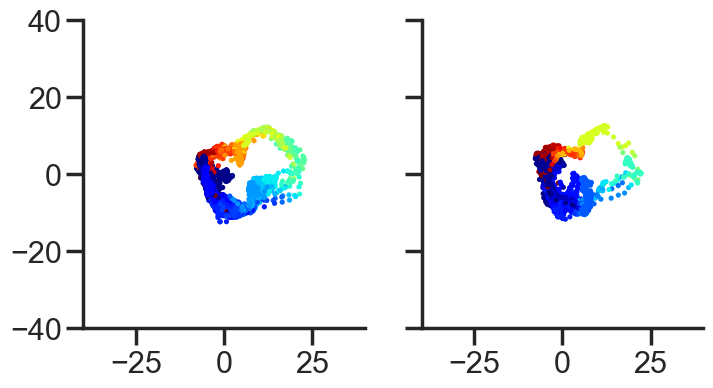

20220802_JA179_lADN_red_H2_VR1_TS7-HF


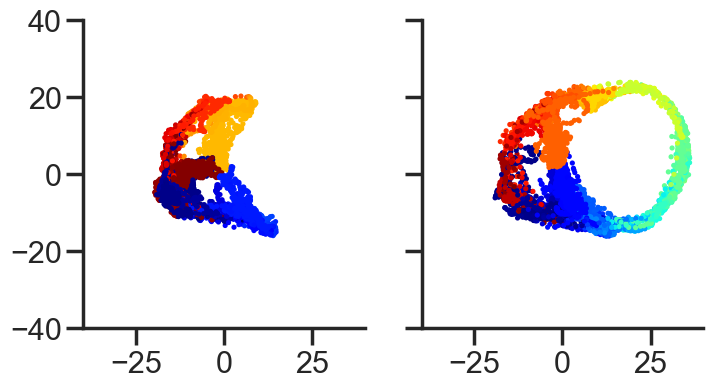

20220804_JA179_lADN_red_H2_VR1_TS7-HF


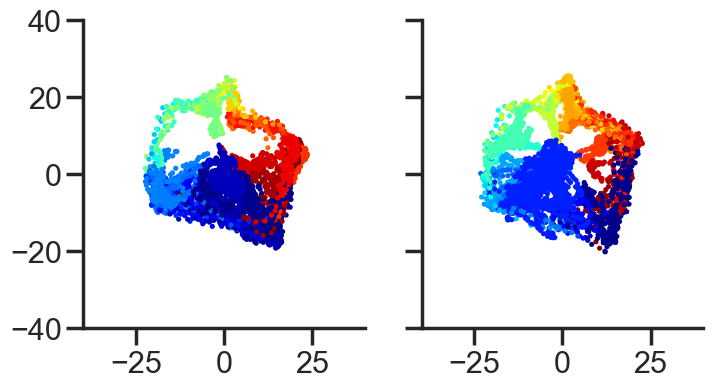

20220805_JA179_lADN_red_H2_VR1_TS7-HF


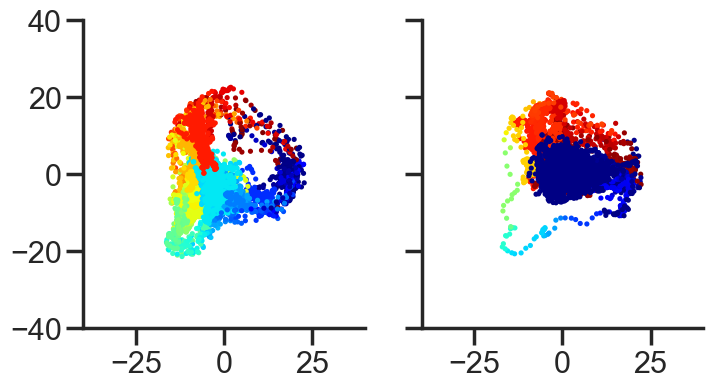

20220809_JA180_lADN_red_H2_VR1_TS7-HF


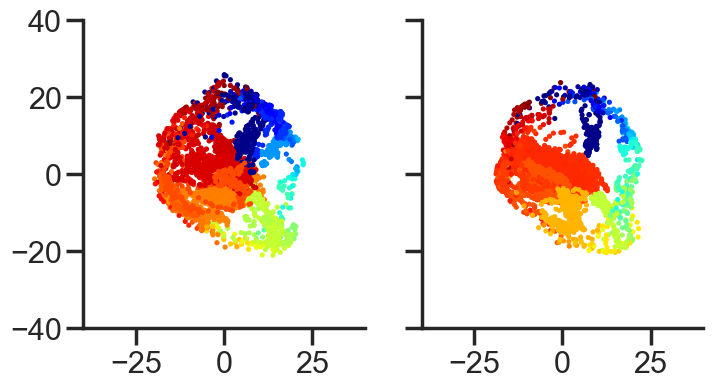

20220810_JA180_lADN_red_H2_VR1_TS7-HF


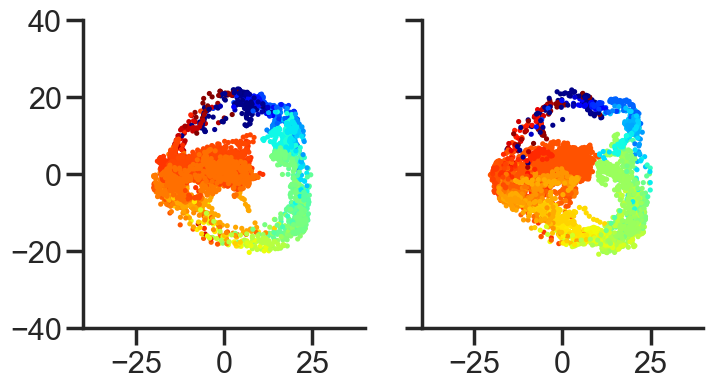

20220811_JA180_lADN_red_H2_VR1_TS7-HF


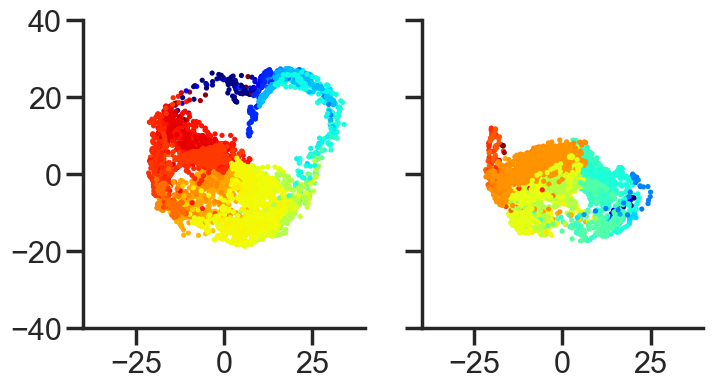

20220819_JA180_lADN_red_H2_VR1_TS7-HF


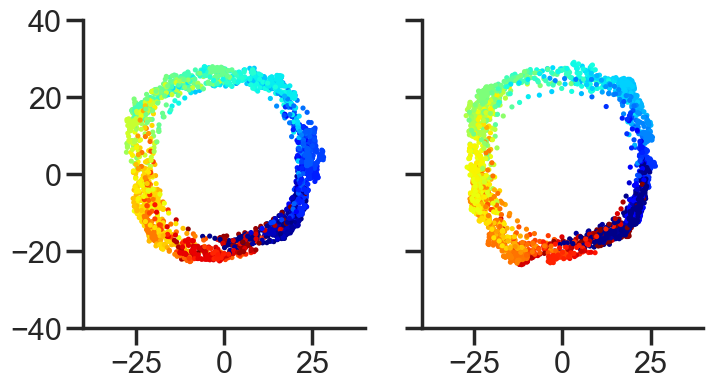

20220809_JA181_lADN_red_H2_VR1_TS7-HF


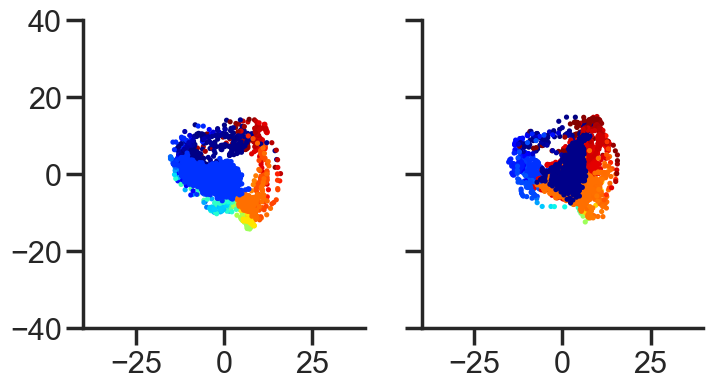

20220812_JA181_lADN_red_H2_VR1_TS7-HF


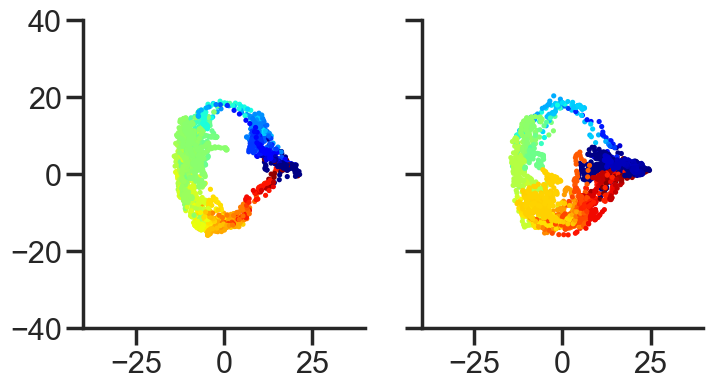

20220627_MC022_lADN_red_H2_VR1_TS7-HF


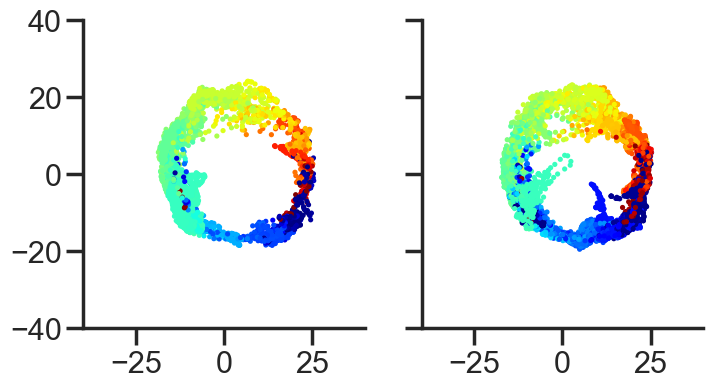

20220629_MC022_lADN_red_H2_VR1_TS7-HF


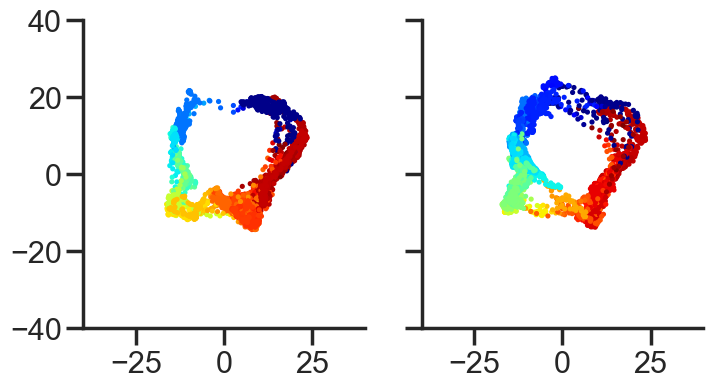

20220829_MC038_lADN_red_H2_VR1_TS7-HF


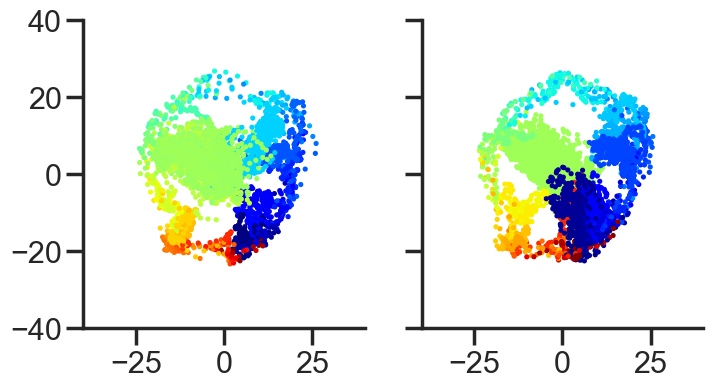

In [98]:
speed_threshold = 5

for k in df_emb_hdc.rec_id.unique():
    if 'TS7-HF' not in k:
        continue
    print(k)


    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    emb_hdc_x, emb_hdc_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    
    lin_speed = tmp_df['lin_speed'].values
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = speed_threshold)
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True
    cxy, rad_manifold = compute_radius(emb_hdc_x, emb_hdc_y, run_mask)
    # get stat epochs
    # stat_epoch = consecutive(stat_idx)
    
    measured_yaw = tmp_df['measured_yaw'].values[:]
    # measured_yaw_rad = np.deg2rad(measured_yaw)
    split_idx = emb_hdc_y.size//2

    f, ax = plt.subplots(1, 2, figsize = (8, 4), sharex = True, sharey = True)
    ax[0].scatter(emb_hdc_x[:split_idx], emb_hdc_y[:split_idx], alpha = 1, s = 3,  c = measured_yaw[:split_idx], 
            cmap = 'jet')
    
    ax[1].scatter(emb_hdc_x[split_idx:], emb_hdc_y[split_idx:], alpha = 1, s = 3,  c = measured_yaw[split_idx:], 
            cmap = 'jet')
    # f.colorbar(ax[1])
    ax[1].set_xlim(-40, 40)
    ax[1].set_ylim(-40, 40)

    plt.show()
    # break

In [94]:
emb_hdc_y.size//2

2675